In [19]:
# install what the whole notebook needs
!pip install -q transformers datasets accelerate peft sentence-transformers rank_bm25 jiwer librosa soundfile evaluate

import os, sys, random, platform
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch

# google drive holds the data, models and results so nothing is lost when the runtime resets
from google.colab import drive, userdata
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Mfasha chatbot")
DATA_DIR    = ROOT / "data"
MODELS_DIR  = ROOT / "models"
RESULTS_DIR = ROOT / "results"
AUDIO_DIR   = ROOT / "audio"

for folder in (DATA_DIR, MODELS_DIR, RESULTS_DIR, AUDIO_DIR):
    folder.mkdir(parents=True, exist_ok=True)


@dataclass(frozen=True)
class Config:
    seed: int = 42

    # datasets on the hugging face hub
    retrieval_repo: str = "C4IR-RW/kinya-ag-retrieval"
    tts_repo: str = "C4IR-RW/kinya-ag-tts"

    # retrieval
    base_embedder: str = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
    top_k: int = 5

    # speech to text
    asr_model: str = "facebook/mms-1b-all"
    asr_lang: str = "kin"
    sample_rate: int = 16000


CFG = Config()


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(CFG.seed)

# keys come from the Colab secrets panel
def get_secret(name):
    try:
        return userdata.get(name)
    except Exception:
        return os.getenv(name)


HF_TOKEN = get_secret("HF_TOKEN")
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("python  :", sys.version.split()[0], f"({platform.system()})")
print("torch   :", torch.__version__)
print("device  :", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "")
print("root    :", ROOT)
print("hf token:", "found" if HF_TOKEN else "missing, add HF_TOKEN in Colab secrets")
if DEVICE == "cpu":
    print("no GPU, go to Runtime > Change runtime type and pick a GPU before training anything")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
python  : 3.13.16 (Linux)
torch   : 2.11.0+cu130
device  : cuda (Tesla T4)
root    : /content/drive/MyDrive/Mfasha chatbot
hf token: found


In [22]:
import re
import csv
import pandas as pd
from huggingface_hub import hf_hub_download

CLEAN_DIR = DATA_DIR / "clean"
CLEAN_DIR.mkdir(exist_ok=True)


def fetch(name):
    return hf_hub_download(CFG.retrieval_repo, name, repo_type="dataset")


def read_lines(name, keep_blank=False):
    with open(fetch(name), encoding="utf-8") as f:
        lines = [l.strip().strip('"') for l in f]
    return lines if keep_blank else [l for l in lines if l]


# the raw text has spaces before punctuation and after apostrophes
# this puts the text back the way it is normally written, so the retrieval model and the voice later get clean input
def clean_text(t):
    t = t.replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"(?<=\w)'\s+(?=\w)", "'", t)
    t = re.sub(r"(\.\s*){2,}", "... ", t)
    t = re.sub(r"\s+([,.;:!?)\]])", r"\1", t)
    t = re.sub(r"([(\[])\s+", r"\1", t)
    t = re.sub(r"\s+", " ", t)
    return t.strip()


def heading_only(t):
    if ":" not in t:
        return len(re.findall(r"\w", t)) < 10
    body = t.split(":", 1)[1]
    return len(re.findall(r"\w", body)) == 0


passage_ids = read_lines("rw_ag_retrieval_passage_id.txt")
passage_raw = read_lines("rw_ag_retrieval_passage_text.txt")
assert len(passage_ids) == len(passage_raw), "passage ids and texts do not line up"

# blank lines are kept for queries so the ids and texts stay matched line by line
query_ids = read_lines("rw_ag_retrieval_query_id.txt", keep_blank=True)
query_raw = read_lines("rw_ag_retrieval_query_text.txt", keep_blank=True)
assert len(query_ids) == len(query_raw), "query ids and texts do not line up"

passages = pd.DataFrame({"pid": passage_ids, "text": [clean_text(t) for t in passage_raw]})
passages["empty"] = passages["text"].map(heading_only)

queries = pd.DataFrame({"qid": query_ids, "text": [clean_text(t) for t in query_raw]})
queries = queries[queries["qid"] != ""].reset_index(drop=True)

bad_pids = set(passages.loc[passages["empty"], "pid"])
good = passages[~passages["empty"]].reset_index(drop=True)
print(f"passages: {len(passages)} total, {len(bad_pids)} heading-only dropped, {len(good)} kept")

qid2text = dict(zip(queries["qid"], queries["text"]))
pid2text = dict(zip(good["pid"], good["text"]))


def load_split(split):
    df = pd.read_csv(
        fetch(f"rw_ag_retrieval_qpntriplets_{split}.tsv"),
        sep="\t", header=None, names=["qid", "pos_pid", "neg_pid"],
        quoting=csv.QUOTE_NONE, dtype=str,
    )
    raw = len(df)
    # keep only rows whose question and positive passage still exist after cleaning
    df = df[df["qid"].isin(qid2text) & df["pos_pid"].isin(pid2text)]
    df = df[df["neg_pid"].isin(pid2text)].reset_index(drop=True)
    pairs = df[["qid", "pos_pid"]].drop_duplicates().reset_index(drop=True)
    return df, pairs, raw


triplets, pairs, raw_rows = {}, {}, {}
for s in ("train", "dev", "test"):
    triplets[s], pairs[s], raw_rows[s] = load_split(s)

summary = pd.DataFrame({
    s: {
        "raw triplet rows": raw_rows[s],
        "usable triplet rows": len(triplets[s]),
        "questions": pairs[s]["qid"].nunique(),
        "distinct passages": pairs[s]["pos_pid"].nunique(),
    } for s in triplets
})
print(summary.to_string(), "\n")

# no question or passage should leak from train into dev or test
q_sets = {s: set(pairs[s]["qid"]) for s in pairs}
p_sets = {s: set(pairs[s]["pos_pid"]) for s in pairs}
print("shared questions  train/dev:", len(q_sets["train"] & q_sets["dev"]), "| train/test:", len(q_sets["train"] & q_sets["test"]))
print(f"test passages also in train: {len(p_sets['test'] & p_sets['train'])} of {len(p_sets['test'])}")
print(f"dev passages also in train : {len(p_sets['dev'] & p_sets['train'])} of {len(p_sets['dev'])}\n")

# look at a few before and after to make sure the cleaning did what we wanted
for i in (0, 1, 2):
    print("before:", passage_raw[i][:160])
    print("after :", passages.loc[i, "text"][:160], "\n")

# save the clean copies in a new folder, ids only for the triplets to keep the files small
good.to_json(CLEAN_DIR / "passages.jsonl", orient="records", lines=True, force_ascii=False)
queries.to_json(CLEAN_DIR / "queries.jsonl", orient="records", lines=True, force_ascii=False)
for s in triplets:
    triplets[s].to_csv(CLEAN_DIR / f"triplets_{s}.csv", index=False)
    pairs[s].to_csv(CLEAN_DIR / f"pairs_{s}.csv", index=False)
print("saved to", CLEAN_DIR)

passages: 984 total, 43 heading-only dropped, 941 kept
                       train    dev   test
raw triplet rows     1901200  19600  32900
usable triplet rows  1731732  18551  31193
questions              18123    196    329
distinct passages        900     10     20 

shared questions  train/dev: 0 | train/test: 0
test passages also in train: 0 of 20
dev passages also in train : 0 of 10

before: Inkoko irwaye irangwa n' ibi bikurikira : Iyo indwara yateye mu nkoko , ibigaragaza ubuzima bwazo bwiza birabura cyangwa bigahinduka . Usanga inkoko zigunze , z
after : Inkoko irwaye irangwa n'ibi bikurikira: Iyo indwara yateye mu nkoko, ibigaragaza ubuzima bwazo bwiza birabura cyangwa bigahinduka. Usanga inkoko zigunze, zikonj 

before: Uburyo indwara y' ubushita yandura mu nkoko : Ino ndwara iboneka mu nkoko zose ( into n' inkuru ) . Ni indwara mbi cyane iterwa na virusi . Inkoko zirwaye zandu
after : Uburyo indwara y'ubushita yandura mu nkoko: Ino ndwara iboneka mu nkoko zose (into n'inku

In [23]:
rng = np.random.default_rng(CFG.seed)
train_pairs = pairs["train"]

# take 50 whole passages out of train and add them to the original dev passages
train_pids = np.array(sorted(train_pairs["pos_pid"].unique()))
rng.shuffle(train_pids)
extra_dev_pids = set(train_pids[:50])
in_extra = train_pairs["pos_pid"].isin(extra_dev_pids)

dev_unseen  = pd.concat([pairs["dev"], train_pairs[in_extra]]).reset_index(drop=True)
test_unseen = pairs["test"].reset_index(drop=True)

# for the passages that stay in training, hold out a few questions each
# these passages are in the search index at test time, like the real chatbot
rest = train_pairs[~in_extra].sample(frac=1, random_state=CFG.seed)
pos_in_passage = rest.groupby("pos_pid").cumcount()
passage_size   = rest.groupby("pos_pid")["qid"].transform("size")
enough = passage_size >= 8                     # skip passages with too few questions

dev_seen  = rest[enough & (pos_in_passage < 2)]
test_seen = rest[enough & (pos_in_passage >= 2) & (pos_in_passage < 4)]
train_final = rest.drop(dev_seen.index).drop(test_seen.index)

splits = {
    "train": train_final,
    "dev_seen": dev_seen,
    "test_seen": test_seen,
    "dev_unseen": dev_unseen,
    "test_unseen": test_unseen,
}

# a question must live in exactly one split
all_qids = [set(df_s["qid"]) for df_s in splits.values()]
assert sum(len(s) for s in all_qids) == len(set().union(*all_qids)), "a question is in two splits"

# an unseen split must not share passages with training
for name in ("dev_unseen", "test_unseen"):
    assert not (set(splits[name]["pos_pid"]) & set(train_final["pos_pid"])), f"{name} leaks into train"

report = pd.DataFrame({
    name: {"questions": len(df_s), "passages": df_s["pos_pid"].nunique()}
    for name, df_s in splits.items()
}).T
print(report.to_string())

SPLIT_DIR = CLEAN_DIR / "splits"
SPLIT_DIR.mkdir(exist_ok=True)
for name, df_s in splits.items():
    df_s.reset_index(drop=True).to_csv(SPLIT_DIR / f"{name}.csv", index=False)
print("saved to", SPLIT_DIR)

             questions  passages
train            14232       850
dev_seen          1394       697
test_seen         1394       697
dev_unseen        1299        60
test_unseen        329        20
saved to /content/drive/MyDrive/Mfasha chatbot/data/clean/splits


In [24]:
import re, gc
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

EMB_DIR = RESULTS_DIR / "emb"
EMB_DIR.mkdir(exist_ok=True)

# True scores every baseline again. needed once after the float32 fix, then set it back to False
REDO_BASELINES = True

passage_pids  = good["pid"].tolist()
passage_texts = good["text"].tolist()
pid2idx = {p: i for i, p in enumerate(passage_pids)}

# one table with every evaluation question, so each model only has to encode them once
eval_names = ["dev_seen", "test_seen", "dev_unseen", "test_unseen"]
ev = pd.concat([splits[n].assign(split=n) for n in eval_names]).reset_index(drop=True)
ev["question"] = ev["qid"].map(qid2text)
questions = ev["question"].tolist()
gold = ev["pos_pid"].map(pid2idx).to_numpy()
print(f"{len(questions)} eval questions, searching {len(passage_texts)} passages")


def tok(text):
    return re.findall(r"\w+", text.lower())


def to_rank(S):
    return np.argsort(np.argsort(-S, axis=1), axis=1) + 1


def rrf(mats, weights, k=60):
    return sum(w / (k + to_rank(S)) for S, w in zip(mats, weights))


def score(S, name):
    S = np.asarray(S, dtype=np.float32)
    g = S[np.arange(len(S)), gold][:, None]
    rank = (S >= g).sum(axis=1)          # ties count against the system
    rows = []
    for split in eval_names:
        m = (ev["split"] == split).to_numpy()
        r = rank[m]
        rows.append({
            "system": name, "split": split,
            "R@1": (r <= 1).mean(), "R@5": (r <= 5).mean(), "R@10": (r <= 10).mean(),
            "MRR@10": np.where(r <= 10, 1 / r, 0).mean(),
        })
    return rows


bm25 = BM25Okapi([tok(t) for t in passage_texts])
S_bm25 = np.vstack([bm25.get_scores(tok(q)) for q in questions])
rows = score(S_bm25, "BM25")

# name: (hub id, query prefix, passage prefix, max length)
embedders = {
    "mpnet (current)":  ("sentence-transformers/paraphrase-multilingual-mpnet-base-v2", "", "", 256),
    "multilingual-e5":  ("intfloat/multilingual-e5-large", "query: ", "passage: ", 512),
    "bge-m3":           ("BAAI/bge-m3", "", "", 512),
    "labse":            ("sentence-transformers/LaBSE", "", "", 256),
}

baseline_csv = RESULTS_DIR / "retrieval_baselines.csv"
if baseline_csv.exists() and not REDO_BASELINES:
    results = pd.read_csv(baseline_csv)
else:
    for name, (hub_id, q_pre, p_pre, max_len) in embedders.items():
        model = SentenceTransformer(hub_id, device=DEVICE, model_kwargs={"torch_dtype": torch.float16})
        model.max_seq_length = max_len

        cache = EMB_DIR / (hub_id.replace("/", "_") + "_passages.npy")
        if cache.exists():
            P = np.load(cache).astype(np.float32)
        else:
            P = model.encode([p_pre + t for t in passage_texts], batch_size=16,
                             normalize_embeddings=True, show_progress_bar=True).astype(np.float32)
            np.save(cache, P)

        Q = model.encode([q_pre + q for q in questions], batch_size=64,
                         normalize_embeddings=True, show_progress_bar=False).astype(np.float32)
        S = Q @ P.T

        rows += score(S, name)
        rows += score(rrf([S_bm25, S], [1.0, 0.5]), f"BM25 + {name}")
        del model
        gc.collect()
        torch.cuda.empty_cache()

    results = pd.DataFrame(rows)
    results.to_csv(baseline_csv, index=False)

for metric in ("R@1", "R@10", "MRR@10"):
    print(f"\n{metric}")
    print(results.pivot(index="system", columns="split", values=metric)[eval_names].round(3).to_string())

4416 eval questions, searching 941 passages


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


R@1
split                   dev_seen  test_seen  dev_unseen  test_unseen
system                                                              
BM25                       0.488      0.487       0.488        0.489
BM25 + bge-m3              0.501      0.493       0.460        0.541
BM25 + labse               0.306      0.290       0.303        0.301
BM25 + mpnet (current)     0.172      0.183       0.196        0.204
BM25 + multilingual-e5     0.524      0.517       0.509        0.468
bge-m3                     0.357      0.348       0.321        0.328
labse                      0.080      0.082       0.082        0.085
mpnet (current)            0.031      0.032       0.031        0.046
multilingual-e5            0.383      0.400       0.393        0.316

R@10
split                   dev_seen  test_seen  dev_unseen  test_unseen
system                                                              
BM25                       0.816      0.814       0.811        0.796
BM25 + bge-m3          

In [25]:
from datasets import Dataset
from transformers import TrainerCallback
from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
from sentence_transformers.training_args import BatchSamplers

BASE_ID = "intfloat/multilingual-e5-large"
OUT_DIR = MODELS_DIR / "kinya-e5-large"
BEST_DIR = OUT_DIR / "best"
Q_PRE, P_PRE = "query: ", "passage: "
EPOCHS = 3
PATIENCE = 2
RETRAIN = False
need_training = RETRAIN or not (BEST_DIR / "config.json").exists()


if need_training:
    train_df = splits["train"].reset_index(drop=True)
    train_q = train_df["qid"].map(qid2text).tolist()
    pos_idx = train_df["pos_pid"].map(pid2idx).to_numpy()
    rng = np.random.default_rng(CFG.seed)

    # bm25 negatives, only from passages that appear as training positives
    train_cols = np.zeros(len(passage_texts), bool)
    train_cols[np.unique(pos_idx)] = True

    S_train = np.vstack([bm25.get_scores(tok(q)) for q in train_q])
    S_train[:, ~train_cols] = -np.inf
    order = np.argsort(-S_train, axis=1)[:, :40]
    hard_idx = []
    for row, p in zip(order, pos_idx):
        wrong = [j for j in row if j != p]
        hard_idx.append(rng.choice(wrong[1:15]))
    del S_train

    train_ds = Dataset.from_dict({
        "anchor":   [Q_PRE + q for q in train_q],
        "positive": [P_PRE + passage_texts[i] for i in pos_idx],
        "negative": [P_PRE + passage_texts[i] for i in hard_idx],
    })

    model = SentenceTransformer(BASE_ID, device=DEVICE)
    model.max_seq_length = 256

    # the 250k word table is half the model and too big for a T4 to train
    model[0].auto_model.embeddings.word_embeddings.weight.requires_grad = False
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_all = sum(p.numel() for p in model.parameters())
    print(f"training {n_train / 1e6:.0f}M of {n_all / 1e6:.0f}M parameters")

    dev_mask = ev["split"].isin(["dev_seen", "dev_unseen"]).to_numpy()
    dev_queries = [Q_PRE + q for q, use_q in zip(questions, dev_mask) if use_q]
    dev_gold = gold[dev_mask]
    dev_split = ev["split"].to_numpy()[dev_mask]


    def dev_scores(m):
        with torch.autocast("cuda", dtype=torch.float16):
            P = m.encode([P_PRE + t for t in passage_texts], batch_size=32, normalize_embeddings=True)
            Q = m.encode(dev_queries, batch_size=64, normalize_embeddings=True)
        S = Q.astype(np.float32) @ P.astype(np.float32).T
        g = S[np.arange(len(S)), dev_gold][:, None]
        rank = (S >= g).sum(axis=1)
        out = {}
        for sp in ("dev_seen", "dev_unseen"):
            r = rank[dev_split == sp]
            out[f"{sp} R@1"] = (r <= 1).mean()
            out[f"{sp} R@10"] = (r <= 10).mean()
        return out


    history = []
    best = {"score": -1.0, "epoch": None, "bad_epochs": 0}


    class EpochCheck(TrainerCallback):
        def on_epoch_end(self, args, state, control, **kwargs):
            epoch = int(round(state.epoch))
            sc = dev_scores(model)
            history.append({"epoch": epoch, **sc})
            now = (sc["dev_seen R@1"] + sc["dev_unseen R@1"]) / 2
            print(f"\nepoch {epoch}: " + " | ".join(f"{k} {v:.3f}" for k, v in sc.items()))
            if now > best["score"]:
                best.update(score=now, epoch=epoch, bad_epochs=0)
                model.save_pretrained(str(BEST_DIR))
                print("new best, saved")
            else:
                best["bad_epochs"] += 1
                if best["bad_epochs"] >= PATIENCE:
                    print("no gain for 2 epochs, stopping")
                    control.should_training_stop = True


    # scale 20 gave good dev scores, so it stays
    loss = losses.CachedMultipleNegativesRankingLoss(model, mini_batch_size=2, scale=20)

    args = SentenceTransformerTrainingArguments(
        output_dir=str(OUT_DIR / "tmp"),
        num_train_epochs=EPOCHS,
        per_device_train_batch_size=64,
        learning_rate=2e-5,
        warmup_ratio=0.1,               # newer transformers warns about this name, it still works
        weight_decay=0.01,
        fp16=True,
        batch_sampler=BatchSamplers.NO_DUPLICATES,
        save_strategy="no",
        logging_steps=50,
        report_to="none",
        seed=CFG.seed,
    )

    trainer = SentenceTransformerTrainer(
        model=model, args=args, train_dataset=train_ds, loss=loss, callbacks=[EpochCheck()]
    )
    trainer.train()

    # the real loss values, saved so the plots never need typed-in numbers
    log = [x for x in trainer.state.log_history if "loss" in x]
    pd.DataFrame({"step": [x["step"] for x in log], "loss": [x["loss"] for x in log]}).to_csv(
        RESULTS_DIR / "retrieval_loss_log.csv", index=False)

    hist = pd.DataFrame(history).set_index("epoch")
    hist.to_csv(RESULTS_DIR / "retrieval_epoch_history.csv")
    print("\ndev score per epoch")
    print(hist.round(3).to_string())
    print("best epoch:", best["epoch"])

    del model, trainer
    gc.collect()
    torch.cuda.empty_cache()
else:
    # the model is already on drive, only the epoch table is needed for the plots
    hist = pd.read_csv(RESULTS_DIR / "retrieval_epoch_history.csv").set_index("epoch")
    print("saved retriever found, skipping training")
    print(hist.round(3).to_string())

# from here it runs in both cases: load the best model and score it
model = SentenceTransformer(str(BEST_DIR), device=DEVICE, model_kwargs={"torch_dtype": torch.float16})
model.max_seq_length = 256

P = model.encode([P_PRE + t for t in passage_texts], batch_size=16, normalize_embeddings=True).astype(np.float32)
Q = model.encode([Q_PRE + q for q in questions], batch_size=64, normalize_embeddings=True).astype(np.float32)
S_ft = Q @ P.T

new_rows = score(S_ft, "e5 fine-tuned")
for w in (0.5, 1.0, 2.0):
    new_rows += score(rrf([S_bm25, S_ft], [1.0, w]), f"BM25 + e5 fine-tuned (w={w})")

keep_systems = ["BM25", "multilingual-e5", "BM25 + multilingual-e5"]
compare = pd.concat([results[results["system"].isin(keep_systems)], pd.DataFrame(new_rows)])
compare = compare[compare["split"].isin(["dev_seen", "dev_unseen"])]
compare.to_csv(RESULTS_DIR / "retrieval_finetuned_dev.csv", index=False)

for metric in ("R@1", "R@10", "MRR@10"):
    print(f"\n{metric}")
    print(compare.pivot(index="system", columns="split", values=metric).round(3).to_string())

saved retriever found, skipping training
       dev_seen R@1  dev_seen R@10  dev_unseen R@1  dev_unseen R@10
epoch                                                              
1             0.886          0.990           0.846            0.975
2             0.912          0.994           0.846            0.981
3             0.912          0.994           0.844            0.978


/tmp/ipykernel_15173/2498294185.py:3: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments, losses
/tmp/ipykernel_15173/2498294185.py:4: DeprecationWarning: Importing from 'sentence_transformers.training_args' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.training_args' instead.
  from sentence_transformers.training_args import BatchSamplers


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]


R@1
split                         dev_seen  dev_unseen
system                                            
BM25                             0.488       0.488
BM25 + e5 fine-tuned (w=0.5)     0.619       0.616
BM25 + e5 fine-tuned (w=1.0)     0.667       0.664
BM25 + e5 fine-tuned (w=2.0)     0.747       0.729
BM25 + multilingual-e5           0.524       0.509
e5 fine-tuned                    0.887       0.847
multilingual-e5                  0.383       0.393

R@10
split                         dev_seen  dev_unseen
system                                            
BM25                             0.816       0.811
BM25 + e5 fine-tuned (w=0.5)     0.888       0.881
BM25 + e5 fine-tuned (w=1.0)     0.921       0.921
BM25 + e5 fine-tuned (w=2.0)     0.968       0.952
BM25 + multilingual-e5           0.849       0.836
e5 fine-tuned                    0.990       0.975
multilingual-e5                  0.706       0.684

MRR@10
split                         dev_seen  dev_unseen
system      

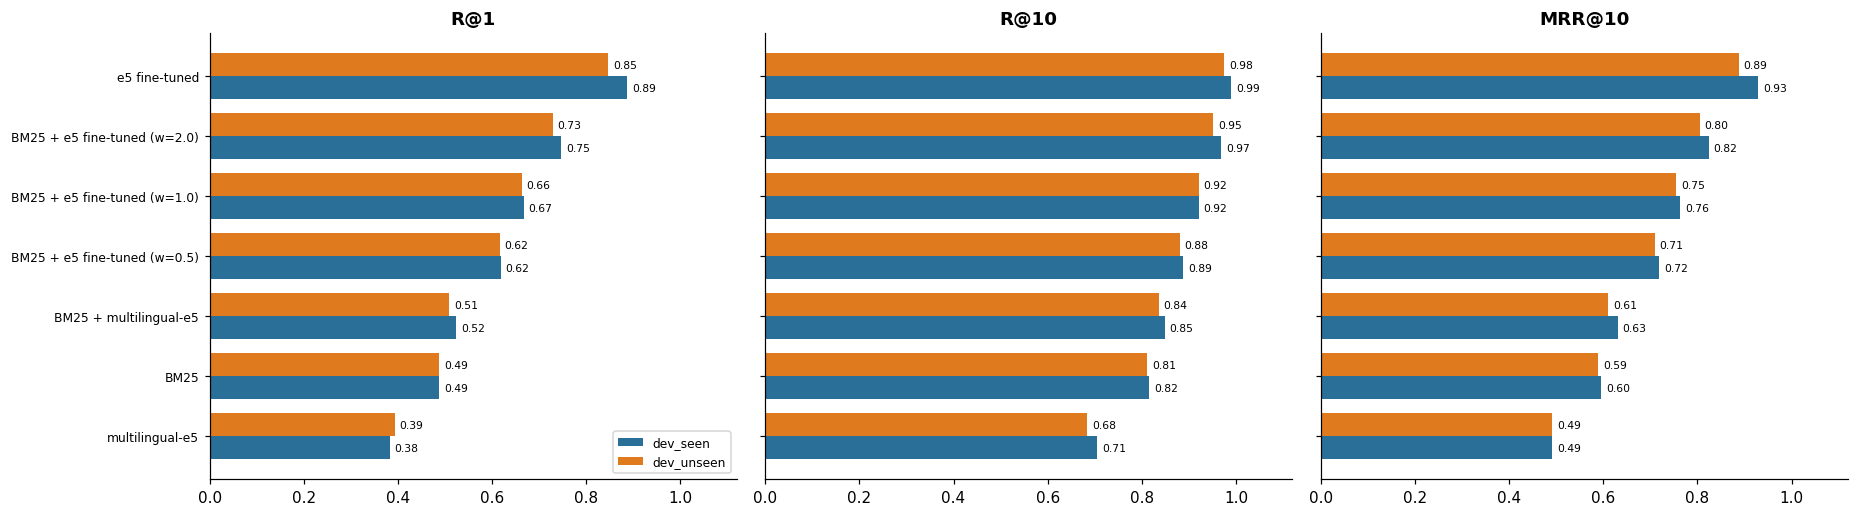

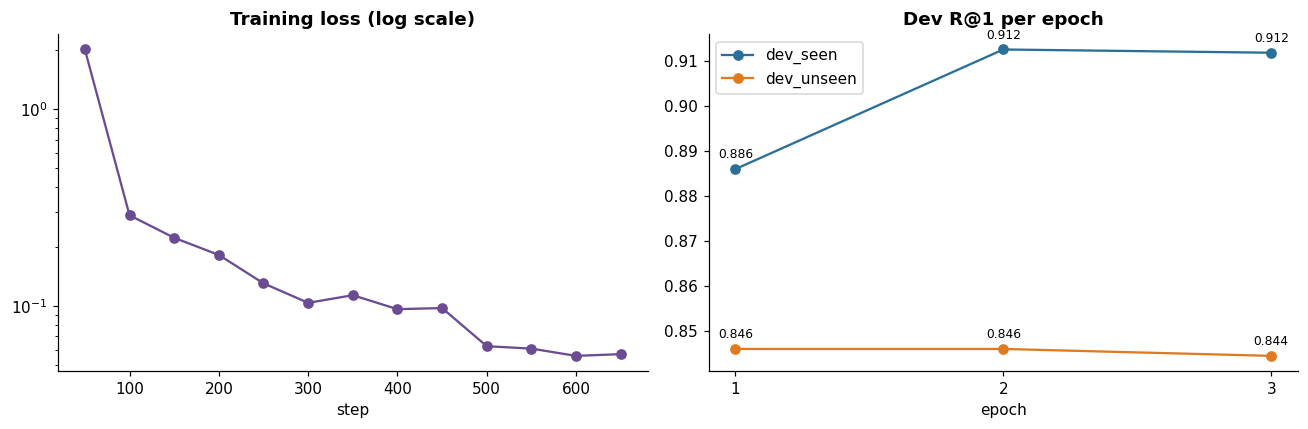

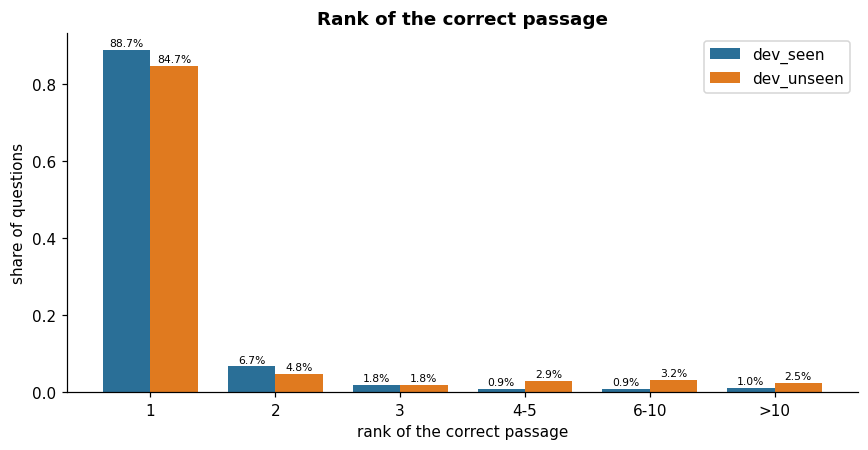

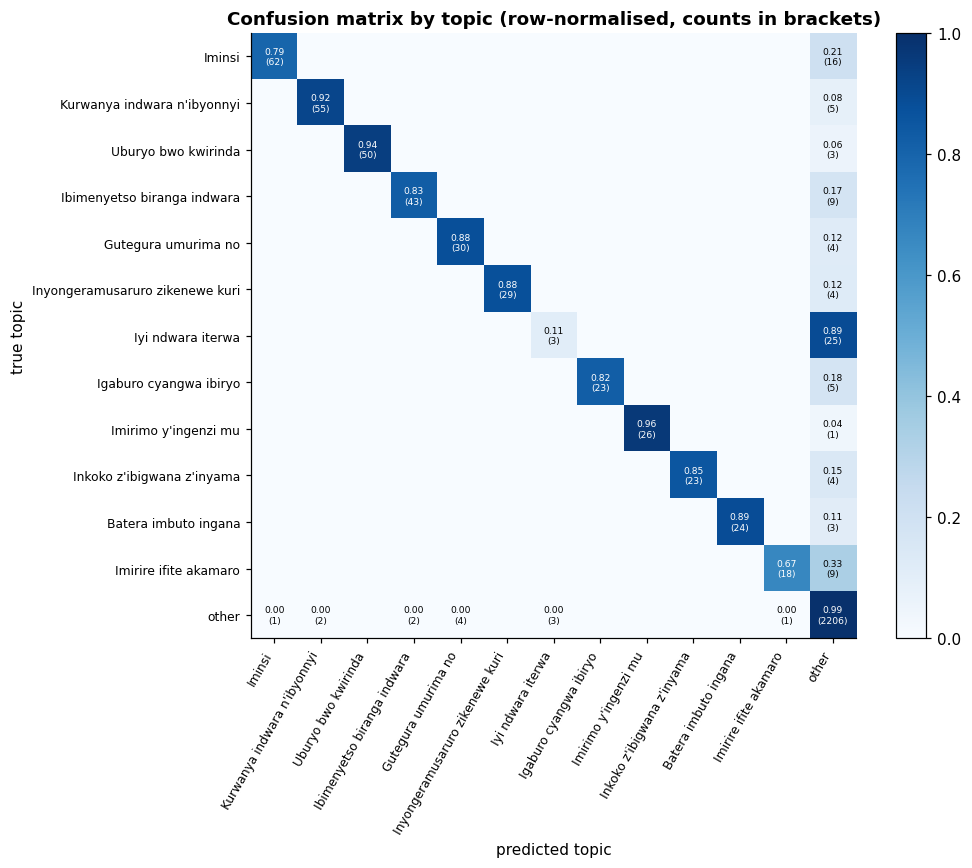

MOST CONFUSED PASSAGE PAIRS (true -> predicted)
 errors true_pid predicted_pid                                                              true_text                                                         predicted_text
     13 A248T675      A246T673 Gukata amashami y'ibiti mu myaka yambere ikurikira iterwa ry'ibiti ni  Ibinyamacunga bikenera amazi menshi kubera ko amatembabuzi ahora atemb
     12 A255T686      A252T683 Iyi ndwara iterwa na bagiteri, yangiza cyane amako menshi y'ibinyamacu Iyi ndwara y'umuhondo w'amababi y'Amacunga, Mandarine n'indimu ni imwe
     10 A255T686      A372T803 Iyi ndwara iterwa na bagiteri, yangiza cyane amako menshi y'ibinyamacu Ibiranga Indwara y'ibihushi muri pome; Imbuto zafashwe zigira ibibara 
      7 A041T027      A030T004 Ubwishingizi butangwa n'ibigo by'ubwishingizi bibititiye ububasha byat Umuhinzi ukeneye ubwishingizi bw'ibihingwa, agana ibigo bitanga ubwish
      7 A754T582      A795T581 Iminsi: 0; Indwara ikingirwa: Marek; Inkingo: CEVAC MD H

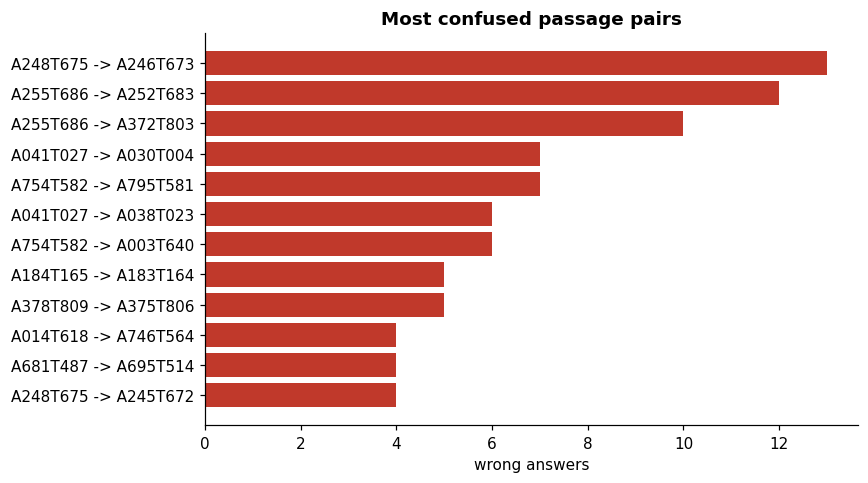


WEAKEST PASSAGES (at least 3 dev questions)
     pid  n   r1                                                                             text
A255T686 26 0.04 Iyi ndwara iterwa na bagiteri, yangiza cyane amako menshi y'ibinyamacunga. Iyi n
A248T675 25 0.12 Gukata amashami y'ibiti mu myaka yambere ikurikira iterwa ry'ibiti ni ngombwa ku
A041T027 25 0.44 Ubwishingizi butangwa n'ibigo by'ubwishingizi bibititiye ububasha byatoranyijwe 
A754T582 27 0.44 Iminsi: 0; Indwara ikingirwa: Marek; Inkingo: CEVAC MD HVT RISPENS; Uko zitangwa
A681T487 27 0.67 Imirire ifite akamaro kanini mu bworozi bw'ingurube kugira ngo bwunguke. Indyo i
A801T839  3 0.67 Gutegura ingwemwe z'ibifenesi bikorwa mu buryo bukurikira: Ingemwe z'ibifenesi z
A378T809 24 0.67 Ako karima k'igikoni kagomba guhingwamo hakurikijwe uburyo busanzwe bwo guhinga,
A014T618 26 0.69 Umubare w'inkoko n'ubuso zakororerwaho, hagendewe kuminsi imishwi imaze: Iminsi 
A495T306 26 0.69 Ibimenyetso birananga indwara y'akaribata (Anthracnose) 

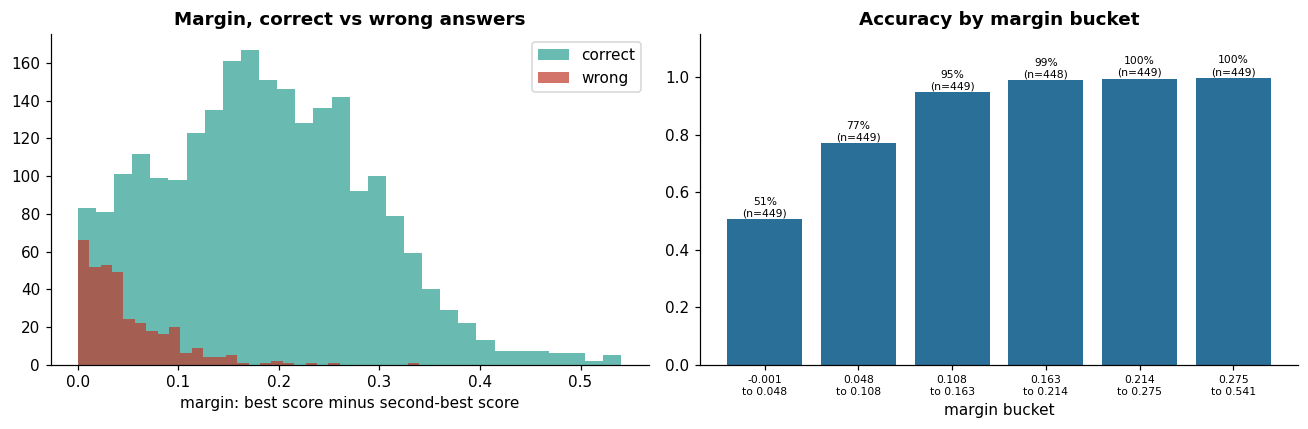

plots saved to /content/drive/MyDrive/Mfasha chatbot/results/plots


In [26]:
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

SHOW = ["dev_seen", "dev_unseen"]
TOPIC_WORDS = 3
TOP_TOPICS = 12
COLORS = {"dev_seen": "#2a6f97", "dev_unseen": "#e07a1f", "test_seen": "#2a6f97", "test_unseen": "#e07a1f"}

PLOT_DIR = RESULTS_DIR / "plots"
PLOT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


# per-question results, all in float32
S = np.asarray(S_ft, dtype=np.float32)
pred = S.argmax(axis=1)
gold_score = S[np.arange(len(S)), gold]
rk = (S >= gold_score[:, None]).sum(axis=1)
srt = np.sort(S, axis=1)
res_df = ev.assign(gold_idx=gold, pred_idx=pred, rk=rk, correct=(pred == gold),
                   top_score=srt[:, -1], margin=srt[:, -1] - srt[:, -2])
dv = res_df[res_df["split"].isin(SHOW)].copy()

# all systems compared
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
order = compare.pivot(index="system", columns="split", values="R@1")[SHOW].mean(axis=1).sort_values().index
for ax, metric in zip(axes, ["R@1", "R@10", "MRR@10"]):
    t = compare.pivot(index="system", columns="split", values=metric).loc[order, SHOW]
    y = np.arange(len(t))
    for k, sp in enumerate(SHOW):
        ax.barh(y + (k - 0.5) * 0.38, t[sp], 0.38, label=sp, color=COLORS[sp])
        for yy, v in zip(y + (k - 0.5) * 0.38, t[sp]):
            ax.text(v + 0.01, yy, f"{v:.2f}", va="center", fontsize=7)
    ax.set_yticks(y)
    ax.set_yticklabels(t.index if ax is axes[0] else [], fontsize=8)
    ax.set_xlim(0, 1.12)
    ax.set_title(metric, fontweight="bold")
axes[0].legend(loc="lower right", fontsize=8)
finish(fig, "1_systems_compared")

#  training curves
loss_file = RESULTS_DIR / "retrieval_loss_log.csv"
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
if loss_file.exists():
    loss_df = pd.read_csv(loss_file)
    ax[0].plot(loss_df["step"], loss_df["loss"], marker="o", color="#6a4c93")
    ax[0].set_yscale("log")
    ax[0].set_xlabel("step")
else:
    ax[0].text(0.5, 0.5, "no loss log yet\n(it is saved the next time the retriever is trained)",
               ha="center", va="center", transform=ax[0].transAxes)
ax[0].set_title("Training loss (log scale)", fontweight="bold")
for col, sp in [("dev_seen R@1", "dev_seen"), ("dev_unseen R@1", "dev_unseen")]:
    ax[1].plot(hist.index, hist[col], marker="o", label=sp, color=COLORS[sp])
    for x, v in zip(hist.index, hist[col]):
        ax[1].annotate(f"{v:.3f}", (x, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax[1].set_xticks(list(hist.index))
ax[1].set_title("Dev R@1 per epoch", fontweight="bold")
ax[1].set_xlabel("epoch")
ax[1].legend()
finish(fig, "2_training_curves")

# rank of the correct passage
bins = [(1, 1, "1"), (2, 2, "2"), (3, 3, "3"), (4, 5, "4-5"), (6, 10, "6-10"), (11, 10**9, ">10")]
fig, ax = plt.subplots(figsize=(8, 4.2))
bar_w = 0.38
for k, sp in enumerate(SHOW):
    r = dv.loc[dv["split"] == sp, "rk"].to_numpy()
    shares = [((r >= a) & (r <= b)).mean() for a, b, _ in bins]
    xs = np.arange(len(bins)) + (k - 0.5) * bar_w
    ax.bar(xs, shares, bar_w, label=sp, color=COLORS[sp])
    for x, s in zip(xs, shares):
        ax.text(x, s + 0.01, f"{s:.1%}", ha="center", fontsize=7)
ax.set_xticks(np.arange(len(bins)))
ax.set_xticklabels([b[2] for b in bins])
ax.set_xlabel("rank of the correct passage")
ax.set_ylabel("share of questions")
ax.set_title("Rank of the correct passage", fontweight="bold")
ax.legend()
finish(fig, "3_rank_distribution")

#  confusion matrix by topic
def topic(t):
    return " ".join(t.split(":", 1)[0].split()[:TOPIC_WORDS])


topics = np.array([topic(t) for t in passage_texts])
true_t, pred_t = topics[dv["gold_idx"].to_numpy()], topics[dv["pred_idx"].to_numpy()]
top_topic_names = pd.Series(true_t).value_counts().head(TOP_TOPICS).index.tolist()
lab = lambda a: np.where(np.isin(a, top_topic_names), a, "other")
labels = top_topic_names + ["other"]
cm = pd.crosstab(lab(true_t), lab(pred_t)).reindex(index=labels, columns=labels, fill_value=0)
cmn = cm.div(cm.sum(axis=1).replace(0, np.nan), axis=0)

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(cmn.to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8)
ax.set_yticklabels(labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm.iat[i, j] > 0:
            v = cmn.iat[i, j]
            ax.text(j, i, f"{v:.2f}\n({cm.iat[i, j]})", ha="center", va="center", fontsize=6,
                    color="white" if v > 0.5 else "black")
ax.set_xlabel("predicted topic")
ax.set_ylabel("true topic")
ax.set_title("Confusion matrix by topic (row-normalised, counts in brackets)", fontweight="bold")
fig.colorbar(im, ax=ax, fraction=0.04)
finish(fig, "4_confusion_topics")

#  most confused passage pairs
wrong_rows = dv[~dv["correct"]]
confused = Counter(zip(wrong_rows["gold_idx"], wrong_rows["pred_idx"])).most_common(12)
pair_df = pd.DataFrame([{
    "errors": n, "true_pid": passage_pids[g], "predicted_pid": passage_pids[p],
    "true_text": passage_texts[g][:70], "predicted_text": passage_texts[p][:70],
} for (g, p), n in confused])
print("MOST CONFUSED PASSAGE PAIRS (true -> predicted)")
print(pair_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([f"{r.true_pid} -> {r.predicted_pid}" for r in pair_df.itertuples()][::-1],
        pair_df["errors"][::-1], color="#c0392b")
ax.set_xlabel("wrong answers")
ax.set_title("Most confused passage pairs", fontweight="bold")
finish(fig, "5_confused_pairs")

# weakest passages
per = dv.groupby("gold_idx").agg(n=("correct", "size"), r1=("correct", "mean")).query("n >= 3")
weak = per.sort_values("r1").head(10).reset_index()
weak["pid"] = [passage_pids[i] for i in weak["gold_idx"]]
weak["text"] = [passage_texts[i][:80] for i in weak["gold_idx"]]
print("\nWEAKEST PASSAGES (at least 3 dev questions)")
print(weak[["pid", "n", "r1", "text"]].round(2).to_string(index=False))

#  confidence
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(dv.loc[dv["correct"], "margin"], bins=30, alpha=0.7, label="correct", color="#2a9d8f")
ax[0].hist(dv.loc[~dv["correct"], "margin"], bins=30, alpha=0.7, label="wrong", color="#c0392b")
ax[0].set_xlabel("margin: best score minus second-best score")
ax[0].set_title("Margin, correct vs wrong answers", fontweight="bold")
ax[0].legend()

dv["margin_bin"] = pd.qcut(dv["margin"], 6, duplicates="drop")
cal = dv.groupby("margin_bin", observed=True)["correct"].agg(["mean", "size"]).reset_index()
ax[1].bar(range(len(cal)), cal["mean"], color="#2a6f97")
ax[1].set_xticks(range(len(cal)))
ax[1].set_xticklabels([f"{b.left:.3f}\nto {b.right:.3f}" for b in cal["margin_bin"]], fontsize=7)
for i, (m, n) in enumerate(zip(cal["mean"], cal["size"])):
    ax[1].text(i, m + 0.01, f"{m:.0%}\n(n={n})", ha="center", fontsize=7)
ax[1].set_ylim(0, 1.15)
ax[1].set_title("Accuracy by margin bucket", fontweight="bold")
ax[1].set_xlabel("margin bucket")
finish(fig, "7_confidence")

print("plots saved to", PLOT_DIR)

In [27]:
model = SentenceTransformer(str(BEST_DIR), device=DEVICE, model_kwargs={"torch_dtype": torch.float16})
model.max_seq_length = 256

P_ft = model.encode([P_PRE + t for t in passage_texts], batch_size=16, normalize_embeddings=True).astype(np.float32)
np.save(EMB_DIR / "kinya_e5_passages.npy", P_ft)

Q_ft = model.encode([Q_PRE + q for q in questions], batch_size=64, normalize_embeddings=True).astype(np.float32)
S_ft = Q_ft @ P_ft.T

test_rows = pd.DataFrame(score(S_ft, "e5 fine-tuned"))
test_rows = test_rows[test_rows["split"].isin(["test_seen", "test_unseen"])]
test_rows.to_csv(RESULTS_DIR / "retrieval_final_test.csv", index=False)
print(test_rows.set_index("split").drop(columns="system").round(3).to_string())


def retrieve(question, k=CFG.top_k):
    q = model.encode([Q_PRE + question], normalize_embeddings=True).astype(np.float32)
    s = (q @ P_ft.T)[0]
    top = np.argsort(-s)[:k]
    return [(passage_pids[i], passage_texts[i], float(s[i])) for i in top]


demo = ev[ev["split"] == "test_unseen"].sample(3, random_state=CFG.seed)
for _, r in demo.iterrows():
    hits = retrieve(r["question"])
    rank = next((n + 1 for n, h in enumerate(hits) if h[0] == r["pos_pid"]), "not in top 5")
    print("question:", r["question"])
    print("right passage rank:", rank)
    print("top hit:", hits[0][1][:160], "\n")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

               R@1    R@5   R@10  MRR@10
split                                   
test_seen    0.893  0.990  0.994   0.936
test_unseen  0.866  0.988  0.994   0.923
question: nu ubuhe buryo umuhinzi abona ubwishingizi bw'ibihingwa?
right passage rank: 1
top hit: Umuhinzi ukeneye ubwishingizi bw'ibihingwa, agana ibigo bitanga ubwishingizi bifitanye amasezerano na MINAGRI cyangwa akegera agoronome w'umurenge ahingamo akam 

question: Umusaruro w'inkwavu uba uhagaze gute?
right passage rank: 1
top hit: Umusaruro w'inkwavuIyo inkwavu zirya ibyatsi gusa zishobora kugira kg 2 zimaze amezi atanu (ubwoko bwa kijyambere). Iyo zirya imvange y'ifu zipima kg 2 zimaze a 

question: Intama zororoka gute?
right passage rank: 1
top hit: Intama zororoka mu buryo bukurikira: Ku ntama 100 zimye, habyara 85; Ku ntama zibyara, havuka abana 140 ku nyarwanda, 180 ku za kijyambere; Intama ibangurirwa b 



In [28]:
import time, json

REFERRAL_MESSAGE = "Mbabarira, nta makuru mfite kuri icyo kibazo."
SOURCE = CFG.retrieval_repo          # where the passage texts come from
REVIEW_STATUS = "reviewed"

# the threshold is worked out from the dev questions, not typed in by hand
# rule: keep this share of the dev questions whose top passage is the right one
COVERAGE = 0.95

dev_mask = ev["split"].isin(["dev_seen", "dev_unseen"]).to_numpy()
S_dev = np.asarray(S_ft, dtype=np.float32)[dev_mask]
dev_top = S_dev.max(axis=1)
dev_right = S_dev.argmax(axis=1) == gold[dev_mask]

REFERRAL_THRESHOLD = float(np.quantile(dev_top[dev_right], 1 - COVERAGE))

served = dev_top >= REFERRAL_THRESHOLD
print(f"retrieval score threshold: {REFERRAL_THRESHOLD:.4f} (cosine similarity, chosen on {len(dev_top)} dev questions)")
print(f"dev questions answered: {served.mean():.1%}")
print(f"right top passage among answered: {dev_right[served].mean():.1%}")
print(f"wrong top passage that would be referred instead: {(~served & ~dev_right).sum()} of {(~dev_right).sum()}")

with open(RESULTS_DIR / "referral_threshold.json", "w") as f:
    json.dump({"threshold": REFERRAL_THRESHOLD, "coverage": COVERAGE,
               "dev_questions": int(len(dev_top))}, f, indent=2)


def _result(question, status, reason, hit, t0):
    answered = status == "answered"
    return {
        "question": question,
        "status": status,                                   # answered or referred
        "referral_reason": reason,                          # None when answered
        "answer": hit[1] if answered else REFERRAL_MESSAGE, # the stored passage, unchanged
        "passage_id": hit[0] if hit else None,
        "retrieval_score": round(hit[2], 4) if hit else None,
        "review_status": REVIEW_STATUS if answered else None,
        "source": SOURCE if answered else None,
        "latency_s": round(time.perf_counter() - t0, 3),
    }


def answer_question(question):
    t0 = time.perf_counter()
    question = (question or "").strip()
    if not question:
        return _result(question, "referred", "empty_question", None, t0)
    hits = retrieve(question)
    if not hits:
        return _result(question, "referred", "no_retrieval_result", None, t0)
    top = hits[0]
    if top[2] < REFERRAL_THRESHOLD:
        return _result(question, "referred", "low_retrieval_score", top, t0)
    return _result(question, "answered", None, top, t0)


# typed text or an audio clip. audio is turned into text first by speech_to_text (defined in the ASR cell)
def ask(text=None, audio=None):
    heard = None
    if audio is not None:
        if "speech_to_text" not in globals():
            raise RuntimeError("speech_to_text is not loaded, run the ASR cell first")
        heard = speech_to_text(audio)
        question = heard
    else:
        question = text
    out = answer_question(question)
    out["heard"] = heard
    return out


print("answer functions ready")

retrieval score threshold: 0.5723 (cosine similarity, chosen on 2693 dev questions)
dev questions answered: 90.5%
right top passage among answered: 91.1%
wrong top passage that would be referred instead: 139 of 356
answer functions ready


In [9]:
needed = ["pd", "np", "ev", "retrieve", "answer_question", "ask",
          "REFERRAL_MESSAGE", "REFERRAL_THRESHOLD", "CFG", "RESULTS_DIR"]
print({n: (n in globals()) for n in needed})

{'pd': True, 'np': True, 'ev': True, 'retrieve': True, 'answer_question': True, 'ask': True, 'REFERRAL_MESSAGE': True, 'REFERRAL_THRESHOLD': True, 'CFG': True, 'RESULTS_DIR': True}


In [10]:
sample = pd.concat([
    ev[ev["split"] == "dev_seen"].sample(3, random_state=CFG.seed),
    ev[ev["split"] == "dev_unseen"].sample(3, random_state=CFG.seed),
])
off_topic = [
    "Ni nde watwaye igikombe cy'isi cya 2022?",
    "Nakora nte porogaramu ya telefoni?",
    "Igiciro cy'itike ya bisi i Kigali ni angahe?",
]
todo = [(r["split"], r["question"], r["pos_pid"]) for _, r in sample.iterrows()] \
     + [("off_topic", q, None) for q in off_topic]

rows = []
for split, q, gold_pid in todo:
    out = ask(text=q)
    top_text = pid2text.get(out["passage_id"], "") if out["passage_id"] else ""
    right = None if gold_pid is None else (out["passage_id"] == gold_pid)
    print("Q      :", q)
    print("status :", out["status"], "| reason:", out["referral_reason"])
    print("passage:", out["passage_id"], "| score:", out["retrieval_score"], "| latency:", out["latency_s"], "s")
    print("top    :", top_text[:200], "\n")
    rows.append({
        "split": split, "question": q, "status": out["status"],
        "referral_reason": out["referral_reason"], "passage_id": out["passage_id"],
        "right_passage": right, "retrieval_score": out["retrieval_score"],
        "latency_s": out["latency_s"], "top_passage": top_text[:300],
    })

samples = pd.DataFrame(rows)
samples.to_csv(RESULTS_DIR / "ask_samples.csv", index=False)

farm = samples[samples["split"] != "off_topic"]
answered = farm[farm["status"] == "answered"]
print(f"farming questions answered: {len(answered)} of {len(farm)}")
print(f"right passage among answered: {int(answered['right_passage'].sum())} of {len(answered)}")
print(f"off-topic questions referred: {(samples[samples['split'] == 'off_topic']['status'] == 'referred').sum()} of 3")

Q      : Muraho neza nitwa Jean Claude ndi umuhinzi nshaka kubabaza amoko ya makadamiya ahingwa hano mu Rwanda?
status : answered | reason: None
passage: A282T713 | score: 0.8117 | latency: 0.065 s
top    : Amoko ya makadamiya ni aya; Makadamiya ifite amoko abiri: hari ubwoko bufite igishishwa cyoroshye n'amavuta menshi (73 - 78 % aribwo Macadamia Integrifolia) arina yo yamamazwa mu Rwanda, muri Afrika n 

Q      : Ese icyonnyi cy'imungu mubigori kirangwa niki?
status : answered | reason: None
passage: A130T110 | score: 0.709 | latency: 0.081 s
top    : Imungu ni agasimba kangiza ibigori mu bigega no mu bubiko. Imungu ikuze ifite uburebure buri hagati ya cm 3 na cm 3, 5 kandi isa n'umukara cyangwe se igihogo kijimye. Ku gice cy'igituza cyayo hagara u 

Q      : Muraho neza nitwa Bugingo ndi umuhinzi ndashaka kubabaza uburyo bwo guhura ibihe?
status : answered | reason: None
passage: A422T231 | score: 0.6006 | latency: 0.081 s
top    : Guhura soya bikorwa mu buryo bukurikira: Guhura Soy

In [11]:
import io, gc, re, json, time, pickle, random, jiwer
import pandas as pd
from huggingface_hub import hf_hub_download


def clean_text(t):
    t = t.replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"(?<=\w)'\s+(?=\w)", "'", t)
    t = re.sub(r"(\.\s*){2,}", "... ", t)
    t = re.sub(r"\s+([,.;:!?)\]])", r"\1", t)
    t = re.sub(r"([(\[])\s+", r"\1", t)
    t = re.sub(r"\s+", " ", t)
    return t.strip()

In [12]:
import io, json, pickle, jiwer
import soundfile as sf, librosa
from concurrent.futures import ThreadPoolExecutor
from huggingface_hub import list_repo_files

HELD_OUT_VOICE = "rw_ag_tts_male2"
N_TEST = 200
TEST_CACHE = DATA_DIR / "asr_test_male2.pkl"

files = list_repo_files(CFG.tts_repo, repo_type="dataset")
wav_set = {f for f in files if f.lower().endswith(".wav")}

tables = []
for tsv in sorted(f for f in files if f.endswith(".tsv")):
    path = hf_hub_download(CFG.tts_repo, tsv, repo_type="dataset")
    raw = pd.read_csv(path, sep="\t", header=None, quoting=3, dtype=str,
                      keep_default_na=False, on_bad_lines="skip")
    df = raw.iloc[:, :2].copy()
    df.columns = ["id", "text"]
    df["id"] = df["id"].str.replace(".wav", "", regex=False).str.strip()
    df["voice"] = tsv[:-4]
    df["wav"] = df["voice"] + "/" + df["id"] + ".wav"
    tables.append(df)

clips = pd.concat(tables, ignore_index=True)
clips = clips[clips["wav"].isin(wav_set)].copy()
clips["key"] = clips["text"].map(lambda t: re.sub(r"\s+", " ", t.strip().lower()))


def has_digit(t):
    return any(ch.isdigit() for ch in t)


ok = clips[(clips["text"].str.strip().str.len() > 10)
           & ~clips["text"].map(has_digit)
           & (clips["text"].str.split().str.len() <= 40)]

held = ok[ok["voice"] == HELD_OUT_VOICE].drop_duplicates("key")
test_keys = sorted(held["key"])
random.Random(CFG.seed).shuffle(test_keys)
test_keys = test_keys[:N_TEST]
(DATA_DIR / "asr_test_keys.json").write_text(json.dumps(test_keys, ensure_ascii=False), encoding="utf-8")
test_rows = held[held["key"].isin(test_keys)].reset_index(drop=True)
print(len(test_rows), "test sentences from", HELD_OUT_VOICE)


def load_wav(path):
    local = hf_hub_download(CFG.tts_repo, path, repo_type="dataset")
    y, sr = sf.read(local, dtype="float32")
    if y.ndim > 1:
        y = y.mean(1)
    if sr != 16000:
        y = librosa.resample(y, orig_sr=sr, target_sr=16000)
    return y


if TEST_CACHE.exists():
    with open(TEST_CACHE, "rb") as f:
        test = pickle.load(f)
else:
    with ThreadPoolExecutor(6) as ex:
        audios = list(ex.map(load_wav, test_rows["wav"]))
    test = [{"audio": a, "text": t, "id": i} for a, t, i in zip(audios, test_rows["text"], test_rows["id"])]
    with open(TEST_CACHE, "wb") as f:
        pickle.dump(test, f)

print(len(test), "clips,", round(sum(len(c["audio"]) for c in test) / 16000 / 60), "minutes of audio")


def norm_strict(t):
    t = t.lower().replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"[^\w' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()


def norm_loose(t):
    return norm_strict(t).replace("'", "")


def messy(t):
    return bool(re.search(r"[()/\[\]]", t)) or any(ord(ch) > 127 and ch not in "\u2019\u2018" for ch in t)


refs = [clean_text(c["text"]) for c in test]
is_clean = np.array([not messy(c["text"]) for c in test])


def wer_of(hyps, idx, norm):
    return jiwer.wer([norm(refs[i]) for i in idx], [norm(hyps[i]) for i in idx])


def report(name, hyps):
    everyone = np.arange(len(refs))
    return {
        "system": name,
        "WER": wer_of(hyps, everyone, norm_strict),
        "WER no apostrophes": wer_of(hyps, everyone, norm_loose),
        "CER": jiwer.cer([norm_strict(r) for r in refs], [norm_strict(h) for h in hyps]),
        "WER clean text only": wer_of(hyps, np.where(is_clean)[0], norm_strict),
    }


def run_mms():
    from transformers import Wav2Vec2ForCTC, AutoProcessor
    proc = AutoProcessor.from_pretrained(CFG.asr_model, target_lang=CFG.asr_lang)
    m = Wav2Vec2ForCTC.from_pretrained(CFG.asr_model, target_lang=CFG.asr_lang,
                                       ignore_mismatched_sizes=True).to(DEVICE).half().eval()
    out = []
    for c in test:
        x = proc(c["audio"], sampling_rate=16000, return_tensors="pt").input_values.to(DEVICE).half()
        with torch.no_grad():
            out.append(proc.decode(m(x).logits.argmax(-1)[0]))
    del m
    return out


# only the stock mms adapter here. the sunbird model needs access approval on hugging face
systems = {"MMS-1b-all (kin adapter)": run_mms}
asr_rows, all_hyps = [], {}
for name, fn in systems.items():
    try:
        t0 = time.time()
        hyps = fn()
        print(f"{name}: done in {time.time() - t0:.0f} s")
    except Exception as e:
        print(f"{name} failed:", str(e)[:300])
        continue
    finally:
        gc.collect()
        torch.cuda.empty_cache()
    all_hyps[name] = hyps
    asr_rows.append(report(name, hyps))

res = pd.DataFrame(asr_rows).set_index("system")
print(res.round(3).to_string())
res.to_csv(RESULTS_DIR / "asr_baselines.csv")
pd.DataFrame({"reference": refs, **all_hyps}).to_csv(RESULTS_DIR / "asr_baseline_outputs.csv", index=False)

for i in np.random.default_rng(CFG.seed).choice(len(test), 4, replace=False):
    print("\nref:", refs[i])
    for name, hyps in all_hyps.items():
        print(f"{name[:10]:10s}:", hyps[i])

rw_ag_tts_female.tsv:   0%|          | 0.00/471k [00:00<?, ?B/s]

rw_ag_tts_female2.tsv:   0%|          | 0.00/314k [00:00<?, ?B/s]

rw_ag_tts_male.tsv:   0%|          | 0.00/471k [00:00<?, ?B/s]

rw_ag_tts_male2.tsv:   0%|          | 0.00/299k [00:00<?, ?B/s]

200 test sentences from rw_ag_tts_male2
200 clips, 19 minutes of audio


...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1096 [00:00<?, ?it/s]

adapter.kin.safetensors: reconstructing file:   0%|          |  0.00B / 9.36MB            

adapter.kin.safetensors: downloading bytes:           |  0.00B            

MMS-1b-all (kin adapter): done in 195 s
                            WER  WER no apostrophes    CER  WER clean text only
system                                                                         
MMS-1b-all (kin adapter)  0.301               0.293  0.063                0.292

ref: Kugira isuku ku mukamyi n'ibikoresho byo gukama
MMS-1b-all: kugira isuku ku mukamyi n'ibikoresho byo gukama

ref: Ibimenyetso birananga indwara y'akaribata (Anthracnose) ko muri puwavuro
MMS-1b-all: ibimenyetso biranga indwara y'akaribata anarakinose ko muri puwavuro

ref: Iyo umworozi akurikirana neza umunsi ku w'undi inkoko ze, ashobora kubona impinduka akamenya niba hari ibitagendaneza arebeye kumatotoro.
MMS-1b-all: iyo imworoza akurikirana neza umunsi ku wundi nkoko ze ashobora kubona impinduka akamenya niba hari ibitagenda neza arebeye ku matotoro

ref: INKA: Inka z'ibyimanyi n'inka z'inzungu
MMS-1b-all: inka inka zibyimanye n'inka z'inzungu


In [13]:
import collections

N_TRAIN_SENT = 3000
N_DEV_SENT = 100
PER_SENT = 2
TRAIN_VOICES = ["rw_ag_tts_female", "rw_ag_tts_female2", "rw_ag_tts_male"]
TRAIN_CACHE = DATA_DIR / "asr_train_dev.pkl"


def bad_label(t):
    return "/" in t or any(ord(ch) > 127 and ch not in "\u2019\u2018" for ch in t)


# same cleaning as the training labels, so a test sentence can never slip into training
test_nkeys = {norm_strict(clean_text(c["text"])) for c in test}

pool = ok[ok["voice"].isin(TRAIN_VOICES)].copy()
pool["label"] = pool["text"].map(lambda t: norm_strict(clean_text(t)))
pool = pool[~pool["label"].isin(test_nkeys) & ~pool["text"].map(bad_label) & (pool["label"].str.len() > 5)]

sentences = sorted(pool["label"].unique())
random.Random(CFG.seed).shuffle(sentences)
dev_s = set(sentences[:N_DEV_SENT])
train_s = set(sentences[N_DEV_SENT:N_DEV_SENT + N_TRAIN_SENT])

shuffled = pool.sample(frac=1, random_state=CFG.seed)
dev_rows = shuffled[shuffled["label"].isin(dev_s)].drop_duplicates("label").assign(split="dev")
train_rows = shuffled[shuffled["label"].isin(train_s)].groupby("label").head(PER_SENT).assign(split="train")
use = pd.concat([train_rows, dev_rows]).reset_index(drop=True)
print(len(use), "clips to fetch |", use["split"].value_counts().to_dict())
assert not (set(use["label"]) & test_nkeys), "a test sentence is in the training data"

counter = [0]


def fetch_clip(path):
    for attempt in range(5):
        try:
            y = load_wav(path)
            counter[0] += 1
            if counter[0] % 500 == 0:
                print("  fetched", counter[0], "of", len(use))
            return y
        except Exception:
            time.sleep(3 * (attempt + 1))
    return None


if TRAIN_CACHE.exists():
    with open(TRAIN_CACHE, "rb") as f:
        data = pickle.load(f)
    print("loaded from Drive")
    # a cache built before the leak fix may hold test sentences, so check it
    leaked = [c for c in data["train"] + data["dev"] if c["text"] in test_nkeys]
    print("test sentences found in the cached training data:", len(leaked))
    if leaked:
        data = {s: [c for c in items if c["text"] not in test_nkeys] for s, items in data.items()}
        print("removed them from the loaded data (the pickle on Drive is unchanged)")
else:
    t0 = time.time()
    with ThreadPoolExecutor(24) as ex:
        audios = list(ex.map(fetch_clip, use["wav"]))
    print(f"download finished in {time.time() - t0:.0f} s")

    failed = sum(y is None for y in audios)
    print("failed downloads:", failed)
    assert failed < 0.05 * len(use), "too many clips failed, run this cell again"

    data = {"train": [], "dev": []}
    filtered = 0
    for (_, r), y in zip(use.iterrows(), audios):
        if y is None or len(y) < 8000 or len(y) > 16000 * 20:
            filtered += 1
            continue
        pcm = (np.clip(y, -1, 1) * 32767).astype(np.int16)
        data[r["split"]].append({"audio": pcm, "text": r["label"], "voice": r["voice"], "id": r["id"]})
    print("left out (failed, too short or too long):", filtered)
    with open(TRAIN_CACHE, "wb") as f:
        pickle.dump(data, f)
    print("saved to Drive")

for s, items in data.items():
    hours = sum(len(c["audio"]) for c in items) / 16000 / 3600
    voices_n = pd.Series([c["voice"] for c in items]).value_counts().to_dict()
    print(f"{s:5s}: {len(items)} clips | {len({c['text'] for c in items})} sentences | {hours:.1f} h | {voices_n}")

char_counts = collections.Counter("".join(c["text"] for c in data["train"]))
odd = {ch: n for ch, n in char_counts.items() if not (ch.isascii() and (ch.isalpha() or ch in "' "))}
print("unusual characters in the labels:", odd if odd else "none")

6087 clips to fetch | {'train': 5987, 'dev': 100}
loaded from Drive
test sentences found in the cached training data: 0
train: 2000 clips | 2000 sentences | 2.4 h | {'rw_ag_tts_female': 757, 'rw_ag_tts_male': 730, 'rw_ag_tts_female2': 513}
dev  : 100 clips | 100 sentences | 0.1 h | {'rw_ag_tts_male': 45, 'rw_ag_tts_female': 38, 'rw_ag_tts_female2': 17}
unusual characters in the labels: none


In [14]:
from scipy.signal import resample_poly
from transformers import Wav2Vec2ForCTC, AutoProcessor, get_linear_schedule_with_warmup

EPOCHS = 6
PATIENCE = 2
LR = 2e-4
MAX_BATCH_SEC = 40

RETRAIN_ASR = False

ADAPTER_DIR = MODELS_DIR / "mms-kin-adapter"
ADAPTER_DIR.mkdir(exist_ok=True)
BEST_PT = ADAPTER_DIR / "best.pt"
DONE_FLAG = ADAPTER_DIR / "training_done.txt"   # written only when training ends normally

need_asr_training = RETRAIN_ASR or not DONE_FLAG.exists()

required = ("data", "test", "report", "asr_rows", "refs", "norm_strict") if need_asr_training else ("test",)
for name in required:
    assert name in globals(), f"'{name}' is missing, run the earlier cells first"


def load_asr():
    p = AutoProcessor.from_pretrained(CFG.asr_model, target_lang=CFG.asr_lang)
    m = Wav2Vec2ForCTC.from_pretrained(CFG.asr_model, target_lang=CFG.asr_lang,
                                       ignore_mismatched_sizes=True).to(DEVICE)
    return p, m


def trainable_state(model):
    return {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}


if need_asr_training:
    gc.collect()
    torch.cuda.empty_cache()
    rnd = random.Random(CFG.seed)
    np_rng = np.random.default_rng(CFG.seed)

    proc, asr_model = load_asr()
    asr_model.config.layerdrop = 0.0
    asr_model.config.ctc_zero_infinity = True

    for n, p in asr_model.named_parameters():
        p.requires_grad = ("adapter" in n) or n.startswith("lm_head")
    params = [p for p in asr_model.parameters() if p.requires_grad]
    n_train, n_all = sum(p.numel() for p in params), sum(p.numel() for p in asr_model.parameters())
    print(f"training {n_train / 1e6:.1f}M of {n_all / 1e6:.0f}M parameters ({100 * n_train / n_all:.2f}%)")

    unk = proc.tokenizer.unk_token_id
    n_unk = sum(unk in proc.tokenizer(c["text"]).input_ids for c in data["train"])
    print("train clips with a character the model does not know:", n_unk)

    def to_float(a):
        return a.astype(np.float32) / 32768.0 if a.dtype == np.int16 else a.astype(np.float32)

    def make_batches(items, max_sec, shuffle):
        idx = list(range(len(items)))
        if shuffle:
            rnd.shuffle(idx)
        batches = []
        for start in range(0, len(idx), 256):
            chunk = sorted(idx[start:start + 256], key=lambda i: len(items[i]["audio"]))
            cur, longest = [], 0
            for i in chunk:
                n = len(items[i]["audio"])
                if cur and max(longest, n) * (len(cur) + 1) > max_sec * 16000:
                    batches.append(cur)
                    cur, longest = [], 0
                cur.append(i)
                longest = max(longest, n)
            if cur:
                batches.append(cur)
        if shuffle:
            rnd.shuffle(batches)
        return batches

    def augment(y):
        if rnd.random() < 0.3:
            y = resample_poly(resample_poly(y, 1, 2), 2, 1)[:len(y)].astype(np.float32)
        if rnd.random() < 0.5:
            snr = rnd.uniform(8, 30)
            power = np.mean(y ** 2) + 1e-8
            y = y + np_rng.standard_normal(len(y)).astype(np.float32) * np.sqrt(power / 10 ** (snr / 10))
        return np.clip(y, -1, 1)

    def collate(items, idxs, train):
        wavs = [augment(to_float(items[i]["audio"])) if train else to_float(items[i]["audio"]) for i in idxs]
        feats = proc.feature_extractor(wavs, sampling_rate=16000, padding=True,
                                       return_attention_mask=True, return_tensors="pt")
        ids = [proc.tokenizer(items[i]["text"]).input_ids for i in idxs]
        labels = torch.full((len(ids), max(map(len, ids))), -100)
        for r, seq in enumerate(ids):
            labels[r, :len(seq)] = torch.tensor(seq)
        return feats.input_values.to(DEVICE), feats.attention_mask.to(DEVICE), labels.to(DEVICE)

    @torch.no_grad()
    def transcribe(items):
        asr_model.eval()
        out = [None] * len(items)
        for idxs in make_batches(items, 60, shuffle=False):
            x, am, _ = collate(items, idxs, train=False)
            with torch.autocast("cuda", dtype=torch.float16):
                logits = asr_model(input_values=x, attention_mask=am).logits
            for i, text in zip(idxs, proc.batch_decode(logits.argmax(-1))):
                out[i] = text.strip()
        return out

    def dev_wer():
        hyps = transcribe(data["dev"])
        return jiwer.wer([norm_strict(c["text"]) for c in data["dev"]], [norm_strict(h) for h in hyps])

    opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.0)
    steps_per_epoch = len(make_batches(data["train"], MAX_BATCH_SEC, shuffle=True))
    total_steps = int(EPOCHS * steps_per_epoch * 1.05)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler()
    print(f"{steps_per_epoch} steps per epoch")

    history = [{"epoch": 0, "dev_wer": dev_wer(), "train_loss": None}]
    print(f"before training: dev WER {history[0]['dev_wer']:.3f}")
    best = {"wer": history[0]["dev_wer"], "epoch": 0, "bad": 0}
    best_state = trainable_state(asr_model)      # the untrained adapter, kept in memory only

    for epoch in range(1, EPOCHS + 1):
        asr_model.train()
        t0, batch_losses = time.time(), []
        for step, idxs in enumerate(make_batches(data["train"], MAX_BATCH_SEC, shuffle=True), 1):
            x, am, y = collate(data["train"], idxs, train=True)
            with torch.autocast("cuda", dtype=torch.float16):
                batch_loss = asr_model(input_values=x, attention_mask=am, labels=y).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(batch_loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            batch_losses.append(batch_loss.item())
            if step % 100 == 0:
                print(f"  epoch {epoch} step {step}/{steps_per_epoch} loss {np.mean(batch_losses[-100:]):.3f} | {time.time() - t0:.0f} s")

        wer = dev_wer()
        history.append({"epoch": epoch, "dev_wer": wer, "train_loss": float(np.mean(batch_losses))})
        print(f"epoch {epoch}: train loss {np.mean(batch_losses):.3f} | dev WER {wer:.3f} | {time.time() - t0:.0f} s")
        if wer < best["wer"]:
            best.update(wer=wer, epoch=epoch, bad=0)
            best_state = trainable_state(asr_model)
            torch.save(best_state, BEST_PT)      # saved on every gain
            print("  new best, saved")
        else:
            best["bad"] += 1
            if best["bad"] >= PATIENCE:
                print(f"  no gain for {PATIENCE} epochs, stopping")
                break

    # keep the best weights, even if that is the untrained adapter
    torch.save(best_state, BEST_PT)
    asr_model.load_state_dict(best_state, strict=False)
    DONE_FLAG.write_text(f"best epoch {best['epoch']}, dev WER {best['wer']:.3f}")
    pd.DataFrame(history).to_csv(RESULTS_DIR / "asr_finetune_history.csv", index=False)
    print("best epoch:", best["epoch"], "| dev WER", round(best["wer"], 3))
    if best["epoch"] == 0:
        print("training did not beat the starting adapter on dev, so the starting adapter is kept")

    hyps = transcribe(test)
    asr_rows = [r for r in asr_rows if r["system"] != "MMS adapter fine-tuned"]
    asr_rows.append(report("MMS adapter fine-tuned", hyps))
    res = pd.DataFrame(asr_rows).set_index("system")
    print("\nTEST SET (held-out voice, 200 clips)")
    print(res.round(3).to_string())
    res.to_csv(RESULTS_DIR / "asr_finetuned_test.csv")
    pd.DataFrame({"reference": refs, "fine-tuned": hyps}).to_csv(RESULTS_DIR / "asr_finetuned_outputs.csv", index=False)
else:
    proc, asr_model = load_asr()
    asr_model.load_state_dict(torch.load(BEST_PT, map_location="cpu"), strict=False)
    print("finished adapter found:", DONE_FLAG.read_text())

asr_model.eval()


# one clip to text. audio can be a file path or a float32 array already at 16 khz
def speech_to_text(audio):
    if isinstance(audio, (str, Path)):
        audio, _ = librosa.load(str(audio), sr=16000, mono=True)
    x = proc.feature_extractor(audio, sampling_rate=16000, return_tensors="pt").input_values.to(DEVICE)
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        logits = asr_model(input_values=x).logits
    return proc.decode(logits.argmax(-1)[0]).strip()


# quick check on one test clip
print("\nreference:", test[0]["text"])
print("heard    :", speech_to_text(test[0]["audio"]))
if "ask" in globals():
    print(ask(text="Intama zororoka gute?"))

Loading weights:   0%|          | 0/1096 [00:00<?, ?it/s]

finished adapter found: best epoch 3, dev WER 0.284

reference: Gutera ubwoko bw’imbuto y’ibirayi bwihanganira iyo ndwara
heard    : gutera ubwoko bw'imbuto y'ibirayi bwihanganira iyo ndwara
{'question': 'Intama zororoka gute?', 'status': 'answered', 'referral_reason': None, 'answer': 'Intama zororoka mu buryo bukurikira: Ku ntama 100 zimye, habyara 85; Ku ntama zibyara, havuka abana 140 ku nyarwanda, 180 ku za kijyambere; Intama ibangurirwa bwa mbere imaze amezi 8 ivutse, icyo gihe iba ifite ibiro hafi 23 ku za kijyambere, na 12 ku Nyarwanda; Isekurume imwe ihagije inyagazi 50, igatangira kwimya ifite amezi 15 ivutse; Intama ihaka iminsi 149 - 152, (amezi 5); Yonsa amezi atatu, ishobora rero kubyara buri mezi 9 iyo yorowe kijyambere; Intama iba ishaje iyo imaze imyaka 6 - 7 ivutse iba itangiye gukuka amenyo); Bahita bayikura mu bworozi.', 'passage_id': 'A712T526', 'retrieval_score': 0.7773, 'review_status': 'unreviewed', 'source': 'C4IR-RW/kinya-ag-retrieval', 'latency_s': 0.035, 'hea

In [15]:
def speech_to_text(audio):
    if isinstance(audio, (str, Path)):
        audio, _ = librosa.load(str(audio), sr=16000, mono=True)
    x = proc.feature_extractor(audio, sampling_rate=16000, return_tensors="pt").input_values.to(DEVICE)
    with torch.no_grad(), torch.autocast(DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda")):
        logits = asr_model(input_values=x).logits
    return proc.decode(logits.argmax(-1)[0]).strip()


print(ask(text="Intama zororoka gute?"))

{'question': 'Intama zororoka gute?', 'status': 'answered', 'referral_reason': None, 'answer': 'Intama zororoka mu buryo bukurikira: Ku ntama 100 zimye, habyara 85; Ku ntama zibyara, havuka abana 140 ku nyarwanda, 180 ku za kijyambere; Intama ibangurirwa bwa mbere imaze amezi 8 ivutse, icyo gihe iba ifite ibiro hafi 23 ku za kijyambere, na 12 ku Nyarwanda; Isekurume imwe ihagije inyagazi 50, igatangira kwimya ifite amezi 15 ivutse; Intama ihaka iminsi 149 - 152, (amezi 5); Yonsa amezi atatu, ishobora rero kubyara buri mezi 9 iyo yorowe kijyambere; Intama iba ishaje iyo imaze imyaka 6 - 7 ivutse iba itangiye gukuka amenyo); Bahita bayikura mu bworozi.', 'passage_id': 'A712T526', 'retrieval_score': 0.7773, 'review_status': 'unreviewed', 'source': 'C4IR-RW/kinya-ag-retrieval', 'latency_s': 0.029, 'heard': None}


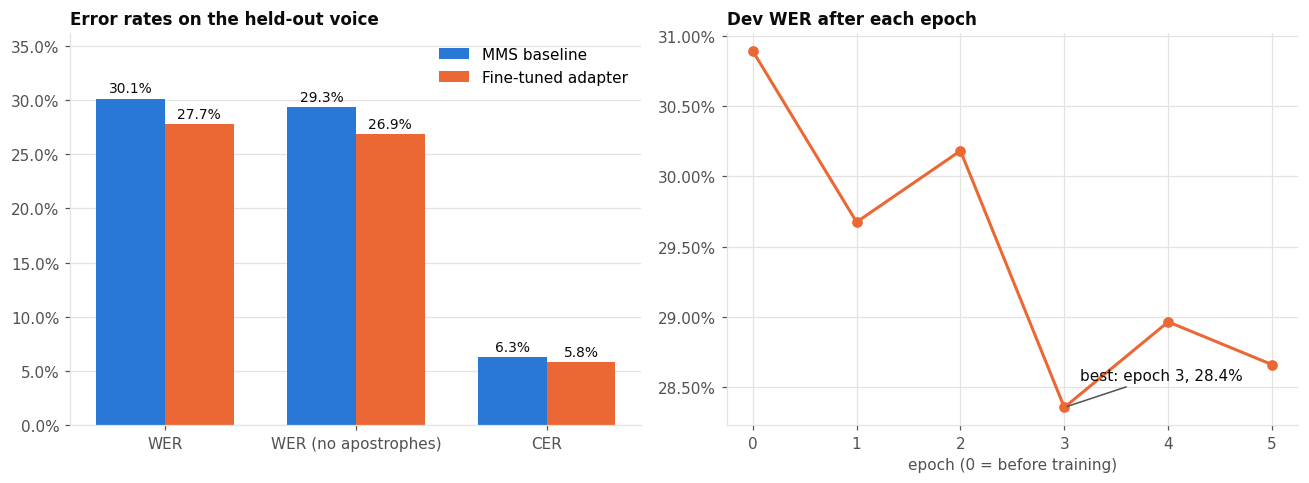

                      baseline  fine-tuned
WER                      0.301       0.277
WER (no apostrophes)     0.293       0.269
CER                      0.063       0.058

what happened to each reference word:
  baseline  : correct 1336 | wrong word 426 | dropped 76 | extra words 52
  fine-tuned: correct 1375 | wrong word 404 | dropped 59 | extra words 47

plot saved to /content/drive/MyDrive/Mfasha chatbot/results/plots/asr_overview.png


In [16]:
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import jiwer

BASE_C, TUNED_C = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "figure.facecolor": "white",
})
PLOT_DIR = RESULTS_DIR / "plots"
PLOT_DIR.mkdir(exist_ok=True)


def norm(t):
    t = str(t).lower().replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"[^\w' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()


base = pd.read_csv(RESULTS_DIR / "asr_baseline_outputs.csv").fillna("")
tuned = pd.read_csv(RESULTS_DIR / "asr_finetuned_outputs.csv").fillna("")
asr_hist = pd.read_csv(RESULTS_DIR / "asr_finetune_history.csv")
assert list(base["reference"]) == list(tuned["reference"]), "the two result files are not in the same order"

keep_i = [i for i, t in enumerate(tuned["reference"]) if norm(t)]
ref = [norm(tuned["reference"][i]) for i in keep_i]
hyp_b = [norm(base["MMS-1b-all (kin adapter)"][i]) for i in keep_i]
hyp_t = [norm(tuned["fine-tuned"][i]) for i in keep_i]


def scores(h):
    return {
        "WER": jiwer.wer(ref, h),
        "WER (no apostrophes)": jiwer.wer([r.replace("'", "") for r in ref], [x.replace("'", "") for x in h]),
        "CER": jiwer.cer(ref, h),
    }


sb, st = scores(hyp_b), scores(hyp_t)

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.5))

# error rates, baseline against fine-tuned
names = list(sb)
x, w = np.arange(len(names)), 0.36
b1 = a.bar(x - w / 2, [sb[n] for n in names], w, color=BASE_C, label="MMS baseline")
b2 = a.bar(x + w / 2, [st[n] for n in names], w, color=TUNED_C, label="Fine-tuned adapter")
for bars in (b1, b2):
    a.bar_label(bars, labels=[f"{v.get_height():.1%}" for v in bars], padding=2, fontsize=9, color=INK)
a.set_xticks(x, names)
a.yaxis.set_major_formatter(PercentFormatter(1))
a.set_ylim(0, max(sb.values()) * 1.2)
a.set_title("Error rates on the held-out voice")
a.legend(frameon=False)
a.grid(axis="x", visible=False)

# dev WER after each training epoch
b.plot(asr_hist["epoch"], asr_hist["dev_wer"], color=TUNED_C, lw=2, marker="o", ms=6)
bi = asr_hist["dev_wer"].idxmin()
b.annotate(f"best: epoch {int(asr_hist['epoch'][bi])}, {asr_hist['dev_wer'][bi]:.1%}",
           (asr_hist["epoch"][bi], asr_hist["dev_wer"][bi]), xytext=(10, 18), textcoords="offset points",
           color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
b.yaxis.set_major_formatter(PercentFormatter(1))
b.set_xlabel("epoch (0 = before training)")
b.set_title("Dev WER after each epoch")

plt.tight_layout()
plt.savefig(PLOT_DIR / "asr_overview.png", dpi=200, facecolor="white")
plt.show()

print(pd.DataFrame({"baseline": sb, "fine-tuned": st}).round(3).to_string())
print("\nwhat happened to each reference word:")
for name, h in (("baseline  ", hyp_b), ("fine-tuned", hyp_t)):
    o = jiwer.process_words(ref, h)
    print(f"  {name}: correct {o.hits} | wrong word {o.substitutions} | dropped {o.deletions} | extra words {o.insertions}")
print("\nplot saved to", PLOT_DIR / "asr_overview.png")

In [3]:
# setup
import os, re, json, time, shutil, threading, gc, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd, torch

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "jiwer", "librosa", "soundfile", "safetensors"])

if "DATA_DIR" not in globals():              # the main notebook (cell 0) already defines these
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/Mfasha chatbot")
    DATA_DIR, MODELS_DIR, RESULTS_DIR = ROOT / "data", ROOT / "models", ROOT / "results"
    for d in (DATA_DIR, MODELS_DIR, RESULTS_DIR):
        d.mkdir(parents=True, exist_ok=True)

try:
    from google.colab import userdata
    if userdata.get("HF_TOKEN"):
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    pass

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42
SR = 16000
TTS_REPO = "C4IR-RW/kinya-ag-tts"
VOICE = "rw_ag_tts_female"
VOICE_OUT = DATA_DIR / "tts_data" / f"{VOICE}_hf2"      # new folder, the first run stays untouched
FT_DIR = MODELS_DIR / "mms-tts-kin-ft2"
WORK_DIR = Path("/content/mms-tts-kin-ft2")
START = Path("/content/mms-kin-train")
LOCAL_DATA = Path("/content/voice_data2")
REPO = Path("/content/finetune-hf-vits")
PKGS = Path("/content/vits_pkgs")
for d in (FT_DIR, WORK_DIR):
    d.mkdir(parents=True, exist_ok=True)


def run(cmd, cwd=None, env=None, quiet=False):
    """Run a shell command. quiet=True prints only the last lines, and only if it fails."""
    p = subprocess.Popen(cmd, shell=True, cwd=cwd, env={**os.environ, **(env or {})},
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    lines = []
    for line in p.stdout:
        lines.append(line)
        if not quiet:
            print(line, end="")
    p.wait()
    if p.returncode:
        if quiet:
            print("".join(lines[-40:]))
        raise RuntimeError(f"command failed (exit {p.returncode}): {cmd[:100]}")
    return "".join(lines)


# the same cleaning the retrieval data got in cell 1 of the main notebook
def clean_text(t):
    t = t.replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"(?<=\w)'\s+(?=\w)", "'", t)
    t = re.sub(r"(\.\s*){2,}", "... ", t)
    t = re.sub(r"\s+([,.;:!?)\]])", r"\1", t)
    t = re.sub(r"([(\[])\s+", r"\1", t)
    return re.sub(r"\s+", " ", t).strip()


# lowercase, no punctuation: for matching sentences and for scoring the round trip
def norm_key(t):
    t = str(t).lower().replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"[^\w' ]+", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def park_models():
    for name in ("asr_model", "model"):
        m = globals().get(name)
        if m is not None and hasattr(m, "to"):
            m.to("cpu")
    for name in ("trainer", "opt", "scaler", "tts"):
        globals().pop(name, None)
    gc.collect()


def unpark_models():
    for name in ("asr_model", "model"):
        m = globals().get(name)
        if m is not None and hasattr(m, "to"):
            m.to(DEVICE)


park_models()
if DEVICE == "cuda":
    torch.cuda.empty_cache()
    print(run("nvidia-smi --query-gpu=name,memory.used,memory.total --format=csv", quiet=True))
else:
    print("NO GPU: Runtime > Change runtime type > pick a GPU before training")
print("voice:", VOICE, "| device:", DEVICE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
name, memory.used [MiB], memory.total [MiB]
Tesla T4, 3 MiB, 15360 MiB

voice: rw_ag_tts_female | device: cuda


In [4]:
#  training data
import soundfile as sf, librosa
from concurrent.futures import ThreadPoolExecutor
from huggingface_hub import list_repo_files, hf_hub_download

N_TRAIN_V, N_VAL_V = 4000, 40


def usable(t):
    # only text the voice says exactly as written
    return (10 < len(t) <= 300 and not any(ch.isdigit() for ch in t)
            and not re.search(r"[()/\[\]]", t) and all(ord(ch) < 128 or ch in "\u2019\u2018" for ch in t))


def prepare_voice_data():
    (VOICE_OUT / "train").mkdir(parents=True, exist_ok=True)
    (VOICE_OUT / "validation").mkdir(parents=True, exist_ok=True)

    wavs = {f for f in list_repo_files(TTS_REPO, repo_type="dataset") if f.lower().endswith(".wav")}
    tsv = hf_hub_download(TTS_REPO, f"{VOICE}.tsv", repo_type="dataset")
    raw = pd.read_csv(tsv, sep="\t", header=None, quoting=3, dtype=str, keep_default_na=False, on_bad_lines="skip")
    vdf = raw.iloc[:, :2].copy()
    vdf.columns = ["id", "text"]
    vdf["id"] = vdf["id"].str.replace(".wav", "", regex=False).str.strip()
    vdf["wav"] = VOICE + "/" + vdf["id"] + ".wav"
    vdf = vdf[vdf["wav"].isin(wavs)].copy()
    vdf["text"] = vdf["text"].map(clean_text)
    vdf["key"] = vdf["text"].map(norm_key)
    vdf = vdf[vdf["text"].map(usable)].drop_duplicates("key")

    keys_file = DATA_DIR / "asr_test_keys.json"
    if keys_file.exists():
        asr_test = {norm_key(k) for k in json.loads(keys_file.read_text(encoding="utf-8"))}
        before = len(vdf)
        vdf = vdf[~vdf["key"].isin(asr_test)]
        print("removed", before - len(vdf), "sentences that are in the ASR test set")

    print("usable sentences for this voice:", len(vdf))
    vdf = vdf.sample(frac=1, random_state=SEED).reset_index(drop=True)
    use = pd.concat([vdf.iloc[N_VAL_V:N_VAL_V + N_TRAIN_V].assign(folder="train"),
                     vdf.iloc[:N_VAL_V].assign(folder="validation")]).reset_index(drop=True)

    def fetch(row):
        target = VOICE_OUT / row["folder"] / f"{row['id']}.wav"
        if target.exists():
            return True
        for attempt in range(5):
            try:
                y, sr = sf.read(hf_hub_download(TTS_REPO, row["wav"], repo_type="dataset"), dtype="float32")
                if y.ndim > 1:
                    y = y.mean(1)
                if sr != SR:
                    y = librosa.resample(y, orig_sr=sr, target_sr=SR)
                sf.write(target, y, SR, subtype="PCM_16")
                return True
            except Exception:
                time.sleep(3 * (attempt + 1))
        return False

    t0 = time.time()
    with ThreadPoolExecutor(24) as ex:
        use["ok"] = list(ex.map(fetch, [r for _, r in use.iterrows()]))
    print(f"downloaded in {time.time() - t0:.0f} s | failed: {(~use['ok']).sum()}")
    for folder in ("train", "validation"):
        part = use[(use["folder"] == folder) & use["ok"]]
        pd.DataFrame({"file_name": part["id"] + ".wav", "text": part["text"]}).to_csv(
            VOICE_OUT / folder / "metadata.csv", index=False)


if (VOICE_OUT / "train" / "metadata.csv").exists() and (VOICE_OUT / "validation" / "metadata.csv").exists():
    print("voice data already on Drive, nothing to do")
else:
    prepare_voice_data()

hours = sum(sf.info(p).duration for p in (VOICE_OUT / "train").glob("*.wav")) / 3600
print(f"{len(list((VOICE_OUT / 'train').glob('*.wav')))} train clips, {hours:.2f} h | {VOICE_OUT}")

voice data already on Drive, nothing to do
3046 train clips, 3.36 h | /content/drive/MyDrive/Mfasha chatbot/data/tts_data/rw_ag_tts_female_hf2


In [5]:
# training code, packages and the starting checkpoint
def patch_all():
    n = 0
    for f in (PKGS / "datasets").rglob("*.py"):
        t = f.read_text(encoding="utf-8")
        if "VideoReader = ()" in t:
            continue
        new = re.sub(r"^([ \t]*)from torchvision\.io import VideoReader[ \t]*$",
                     lambda m: (f"{m.group(1)}try:\n{m.group(1)}    from torchvision.io import VideoReader\n"
                                f"{m.group(1)}except ImportError:\n{m.group(1)}    VideoReader = ()"),
                     t, flags=re.M)
        if new != t:
            f.write_text(new, encoding="utf-8")
            n += 1
    print("datasets files patched:", n)

    # newer transformers has no pad_token_id on VitsConfig
    n = 0
    for f in REPO.rglob("*.py"):
        t = f.read_text(encoding="utf-8")
        new = re.sub(r"(?<![\w.])self\.config\.pad_token_id\b(?!\s*=[^=])", 'getattr(self.config, "pad_token_id", None)', t)
        new = re.sub(r"(?<![\w.])config\.pad_token_id\b(?!\s*=[^=])", 'getattr(config, "pad_token_id", None)', new)
        if new != t:
            f.write_text(new, encoding="utf-8")
            n += 1
    print("repo files patched (pad_token_id):", n)

    # training script
    script = REPO / "run_vits_finetuning.py"
    t = script.read_text(encoding="utf-8")
    old = "from transformers.utils import send_example_telemetry"
    if old in t:
        script.write_text(t.replace(old, "send_example_telemetry = lambda *args, **kwargs: None"), encoding="utf-8")
        print("training script patched")


if not (REPO / "run_vits_finetuning.py").exists():
    run(f"git clone -q https://github.com/ylacombe/finetune-hf-vits.git {REPO}", quiet=True)
if not (PKGS / "datasets").exists():
    run("pip install -q Cython matplotlib tensorboard", quiet=True)
    run(f'pip install -q --target {PKGS} "datasets[audio]"', quiet=True)
if not list((REPO / "monotonic_align").rglob("core*.so")):
    run(f"mkdir -p monotonic_align && {sys.executable} setup.py build_ext --inplace", cwd=REPO / "monotonic_align", quiet=True)

patch_all()

if not (START / "config.json").exists():
    run(f"{sys.executable} convert_original_discriminator_checkpoint.py --language_code kin "
        f"--pytorch_dump_folder_path {START}", cwd=REPO, quiet=True)

# the training clips go to local disk, much faster than reading from Drive
if not (LOCAL_DATA / "train").exists():
    shutil.copytree(VOICE_OUT, LOCAL_DATA)

print("start checkpoint:", (START / "config.json").exists())
print("local clips     :", len(list((LOCAL_DATA / "train").glob("*.wav"))))

datasets files patched: 0
repo files patched (pad_token_id): 0
start checkpoint: True
local clips     : 3046


In [6]:
#  training
VOICE_EPOCHS = 12


def dir_mb(p):
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e6


def valid_checkpoints(folder):
    # a real checkpoint is about 1 GB, anything small is an interrupted save
    return sorted((p for p in folder.glob("checkpoint-*") if p.is_dir() and dir_mb(p) > 300),
                  key=lambda p: int(p.name.split("-")[1]))


def has_final(folder):
    return (folder / "model.safetensors").exists() or (folder / "pytorch_model.bin").exists()


def sync_once():
    for ck in valid_checkpoints(WORK_DIR):
        target = FT_DIR / ck.name
        if target.exists():
            continue
        size = dir_mb(ck)
        time.sleep(20)
        if dir_mb(ck) != size:
            continue
        tmp = FT_DIR / f"_tmp_{ck.name}"
        shutil.rmtree(tmp, ignore_errors=True)
        try:
            shutil.copytree(ck, tmp)
            tmp.rename(target)
            print(f"[sync] {ck.name} saved to Drive")
        except Exception as e:
            print("[sync] failed:", str(e)[:120])
            shutil.rmtree(tmp, ignore_errors=True)
            continue
        for old in valid_checkpoints(FT_DIR)[:-2]:
            shutil.rmtree(old, ignore_errors=True)


def patch_training_script():
    """The training script was written for transformers 4. These removed arguments are read in the script itself."""
    script = REPO / "run_vits_finetuning.py"
    t = script.read_text(encoding="utf-8")
    new = t.replace("from transformers.utils import send_example_telemetry",
                    "send_example_telemetry = lambda *args, **kwargs: None")
    new = re.sub(r"\bnot training_args\.overwrite_output_dir\b", "False", new)
    new = new.replace("training_args.group_by_length", 'getattr(training_args, "group_by_length", False)')
    new = new.replace("training_args.logging_dir", 'getattr(training_args, "logging_dir", None) or "runs"')
    if new != t:
        script.write_text(new, encoding="utf-8")
        print("training script patched for transformers 5")


    model_file = REPO / "utils" / "modeling_vits_training.py"
    m = model_file.read_text(encoding="utf-8")
    head, sep, tail = m.partition("class VitsDiscriminator(VitsPreTrainedModel):")
    body, sep2, rest = tail.partition("\n    def forward(self, hidden_states):")
    if sep and sep2 and "self.post_init()" not in body:
        body = body.rstrip() + "\n\n        self.post_init()\n"
        model_file.write_text(head + sep + body + sep2 + rest, encoding="utf-8")
        print("discriminator class patched for transformers 5")


def check_packages():
    """Make sure only `datasets` comes from vits_pkgs and that training can import everything and decode audio."""
    shadow = [n for n in ("torch", "torchvision", "torchaudio", "numpy", "pandas", "pyarrow", "transformers",
                          "huggingface_hub", "peft", "accelerate") if (PKGS / n).exists()]
    if shadow or not (PKGS / "datasets").exists():
        if shadow:
            print("vits_pkgs holds its own copy of", shadow, "which breaks transformers, rebuilding it with datasets only")
        shutil.rmtree(PKGS, ignore_errors=True)
        run(f'pip install -q --target {PKGS} --no-deps "datasets<4"', quiet=True)
        run("pip install -q dill multiprocess xxhash", quiet=True)
        if "patch_all" in globals():
            patch_all()
    probe = Path("/content/probe_env.py")
    probe.write_text(f"""
import torch, datasets
from transformers import TrainingArguments
ds = datasets.load_dataset(r"{LOCAL_DATA}", split="train").cast_column("audio", datasets.Audio(sampling_rate=16000))
x = ds[0]["audio"]
try:
    n = len(x["array"])
except Exception:
    n = x.get_all_samples().data.shape[-1]
print("TORCH", torch.__file__)
print("DATASETS", datasets.__version__, datasets.__file__)
print("AUDIO_OK", n)
""", encoding="utf-8")
    out = run(f"{sys.executable} {probe}", env={"PYTHONPATH": str(PKGS), "USE_TF": "0"}, quiet=True)
    print("\n".join(l for l in out.splitlines() if l.startswith(("TORCH", "DATASETS", "AUDIO_OK"))))
    assert "vits_pkgs/torch" not in out, "torch still comes from vits_pkgs"
    assert "vits_pkgs/datasets" in out and "AUDIO_OK" in out, "datasets or audio decoding is not working"


if has_final(FT_DIR):
    print("the final voice is already on Drive, skipping training. Delete", FT_DIR, "to train again.")
else:
    # clean out interrupted saves
    for folder in (FT_DIR, WORK_DIR):
        for p in list(folder.glob("checkpoint-*")) + list(folder.glob("_tmp_*")):
            if p.is_dir() and (p.name.startswith("_tmp_") or dir_mb(p) <= 300):
                print("removing incomplete", p.name)
                shutil.rmtree(p, ignore_errors=True)

    # after a runtime reset the local folder is empty
    if not valid_checkpoints(WORK_DIR):
        on_drive = valid_checkpoints(FT_DIR)
        if on_drive:
            print("restoring", on_drive[-1].name, "from Drive")
            shutil.copytree(on_drive[-1], WORK_DIR / on_drive[-1].name)
        for f in FT_DIR.iterdir():
            if f.is_file() and not (WORK_DIR / f.name).exists():
                shutil.copy2(f, WORK_DIR / f.name)
    resuming = bool(valid_checkpoints(WORK_DIR))

    cfg = {
        "project_name": "kinya_agri_voice", "push_to_hub": False, "report_to": ["tensorboard"],
        "output_dir": str(WORK_DIR),
        "dataset_name": str(LOCAL_DATA), "dataset_config_name": None,
        "audio_column_name": "audio", "text_column_name": "text",
        "train_split_name": "train", "eval_split_name": "validation",
        "do_lower_case": True, "full_generation_sample_text": "intama zororoka mu buryo bukurikira",
        "max_duration_in_seconds": 20, "min_duration_in_seconds": 1.0, "max_tokens_length": 500,
        "model_name_or_path": str(START), "preprocessing_num_workers": 2,
        "do_train": True, "num_train_epochs": VOICE_EPOCHS, "gradient_accumulation_steps": 1,
        "gradient_checkpointing": False, "per_device_train_batch_size": 16,
        "learning_rate": 1e-5, "adam_beta1": 0.8, "adam_beta2": 0.99, "warmup_steps": 0.01,
        "do_eval": False, "do_step_schedule_per_epoch": True,
        "save_steps": 250, "save_total_limit": 12,
        "weight_disc": 3, "weight_fmaps": 1, "weight_gen": 1, "weight_kl": 1.5,
        "weight_duration": 1, "weight_mel": 35,
        "fp16": True, "seed": 456,
    }
    if resuming:
        cfg["resume_from_checkpoint"] = "latest"
        print("resuming from", valid_checkpoints(WORK_DIR)[-1].name)
    Path("/content/voice_config.json").write_text(json.dumps(cfg, indent=2), encoding="utf-8")

    patch_training_script()
    check_packages()

    stop = threading.Event()

    def sync_loop():
        while not stop.is_set():
            try:
                sync_once()
            except Exception as e:
                print("[sync] error:", str(e)[:120])
            stop.wait(60)

    syncer = threading.Thread(target=sync_loop, daemon=True)
    syncer.start()
    try:
        run(f"{sys.executable} -u -m accelerate.commands.launch --num_processes 1 --mixed_precision fp16 "
            f"run_vits_finetuning.py /content/voice_config.json",
            cwd=REPO, env={"USE_TF": "0", "PYTHONUNBUFFERED": "1", "PYTHONPATH": str(PKGS)})
    finally:
        stop.set()
        syncer.join(timeout=5)
        sync_once()
        for f in WORK_DIR.iterdir():
            if f.is_file():
                shutil.copy2(f, FT_DIR / f.name)

    print("final voice saved to Drive:", has_final(FT_DIR))

resuming from checkpoint-1500
TORCH /usr/local/lib/python3.13/dist-packages/torch/__init__.py
DATASETS 3.6.0 /content/vits_pkgs/datasets/__init__.py
AUDIO_OK 28979
The following values were not passed to `accelerate launch` and had defaults used instead:
	`--num_machines` was set to a value of `1`
	`--dynamo_backend` was set to a value of `'no'`
To avoid this warning pass in values for each of the problematic parameters or run `accelerate config`.
10/30/2026 05:28:28 - WARNING - __main__ - Process rank: -1, device: cuda:0, n_gpu: 1distributed training: False, 16-bits training: True
10/30/2026 05:28:28 - INFO - __main__ - Training/evaluation parameters VITSTrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.8,
adam_beta2=0.99,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across

In [17]:
# load the voice and compare it with the stock one.
import scipy.io.wavfile as wavfile
from safetensors.torch import load_file
from transformers import VitsModel, AutoTokenizer
from IPython.display import Audio, display


def load_voice(path):
    return VitsModel.from_pretrained(path).to(DEVICE).eval(), AutoTokenizer.from_pretrained(path)


def load_tuned_voice():
    """The final model if training finished, otherwise the newest good checkpoint on Drive."""
    try:
        tok = AutoTokenizer.from_pretrained(str(FT_DIR))
    except Exception:
        tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kin")
    if (FT_DIR / "model.safetensors").exists() or (FT_DIR / "pytorch_model.bin").exists():
        print("tuned voice: final model")
        return VitsModel.from_pretrained(str(FT_DIR)).to(DEVICE).eval(), tok
    ckpts = sorted((p for p in FT_DIR.glob("checkpoint-*") if (p / "model.safetensors").exists()),
                   key=lambda p: int(p.name.split("-")[1]))
    assert ckpts, "no fine-tuned weights on Drive yet, run cell 21 first"
    print("tuned voice: training is not finished, using", ckpts[-1].name)
    m = VitsModel.from_pretrained("facebook/mms-tts-kin")
    missing, unexpected = m.load_state_dict(load_file(str(ckpts[-1] / "model.safetensors")), strict=False)
    print(f"  missing keys: {len(missing)} | ignored keys (discriminator etc.): {len(unexpected)}")
    assert not missing, f"the checkpoint does not fit the voice model, for example {missing[:3]}"
    return m.to(DEVICE).eval(), tok


def say(m, tk, text):
    inputs = tk(text.lower(), return_tensors="pt").to(DEVICE)
    torch.manual_seed(0)
    with torch.no_grad():
        return m(**inputs).waveform[0].cpu().numpy()


unpark_models()            # the retriever and the ASR go back on the GPU
voice_stock = load_voice("facebook/mms-tts-kin")
voice_tuned = load_tuned_voice()
tts, tts_tok = voice_tuned

voice_tests = [
    "Intama zororoka mu buryo bukurikira",
    "Umuhinzi ukeneye ubwishingizi bw'ibihingwa agana ibigo bitanga ubwishingizi",
    "Inkoko zirwaye zanduza izindi",
]
(RESULTS_DIR / "tts_samples").mkdir(exist_ok=True)
for i, t in enumerate(voice_tests):
    for name, (m, tk) in (("stock", voice_stock), ("tuned", voice_tuned)):
        wav = say(m, tk, t)
        wavfile.write(RESULTS_DIR / "tts_samples" / f"{i}_{name}_v2.wav", SR, wav)
        print(f"{name}: {t}")
        display(Audio(wav, rate=SR))

Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

tuned voice: final model


Loading weights:   0%|          | 0/762 [00:00<?, ?it/s]

[transformers] VitsModel LOAD REPORT from: /content/drive/MyDrive/Mfasha chatbot/models/mms-tts-kin-ft2
Key                                                                             | Status     |  | 
--------------------------------------------------------------------------------+------------+--+-
discriminator.discriminators.{0, 1, 2, 3, 4, 5}.convs.{0, 1, 2, 3, 4, 5}.bias   | UNEXPECTED |  | 
discriminator.discriminators.{0, 1, 2, 3, 4, 5}.convs.{0, 1, 2, 3, 4, 5}.weight | UNEXPECTED |  | 
discriminator.discriminators.{0, 1, 2, 3, 4, 5}.final_conv.bias                 | UNEXPECTED |  | 
discriminator.discriminators.{0, 1, 2, 3, 4, 5}.final_conv.weight               | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


stock: Intama zororoka mu buryo bukurikira


tuned: Intama zororoka mu buryo bukurikira


stock: Umuhinzi ukeneye ubwishingizi bw'ibihingwa agana ibigo bitanga ubwishingizi


tuned: Umuhinzi ukeneye ubwishingizi bw'ibihingwa agana ibigo bitanga ubwishingizi


stock: Inkoko zirwaye zanduza izindi


tuned: Inkoko zirwaye zanduza izindi
